# Projet PFA — Prédiction du churn clients

## Introduction
Dans les télécoms, la **résiliation (churn)** pèse lourd : perdre un client coûte plus cher que le fidéliser.  
But du projet : construire un **modèle de prédiction** qui estime, pour chaque client, le risque de départ afin d’agir **avant** la résiliation (offres ciblées, actions proactives).

---

## Objectifs
1. Utiliser le jeu de données **Telco Customer Churn**.
2. Réaliser une **EDA** simple pour comprendre tendances et variables clés.
3. Entraîner plusieurs modèles (p.ex. **Régression logistique**, **Random Forest**, **XGBoost**).
4. Évaluer avec des métriques adaptées (**Accuracy**, **Precision**, **Recall**, **F1**, **ROC-AUC**).
5. Optimiser par **recherche d’hyperparamètres**.
6. Déployer une mini **app Flask** pour tester des prédictions réelles.
7. Produire une **documentation claire** + **rapport final**.

---

## Approche (vue rapide)
- **Prétraitement** : nettoyage, types corrects, features dérivées si utile.  
- **Encodage** : One-Hot pour les variables catégorielles, mise à l’échelle au besoin.  
- **Équilibrage** : SMOTE / under-sampling si la cible est déséquilibrée.  
- **Split** : train / validation (stratifié).  
- **Modèles** : LogReg, RF, XGBoost (tuning léger).  
- **Évaluation** : priorité à **AUC** et **F1** ; suivi de Recall/Precision.  
- **Seuil de décision** : ajusté selon l’objectif métier (plus de **Recall** vs moins de faux positifs).  
- **Interprétabilité** : coefficients (LogReg) / importances (RF/XGB).

---

## Déploiement & livrables
- **Application Flask** : formulaire → prédiction + explication courte.  
- **Artifacts** :  
  - `models/best_model.pkl` (pipeline complet prêt pour l’inférence)  
  - `models/schema.json` (colonnes, types, encodage)  
- **Docs** : notebooks propres (EDA, training, comparaison), `README.md`, **rapport PDF** (méthodo, résultats, limites, pistes futures).

---

## Valeur ajoutée
- Vision claire des **facteurs du churn**.  
- Outil **prédictif et actionnable** pour marketing/CRM.  
- Processus **reproductible** et **généralisable** à d’autres contextes.


## Bibliothèques nécessaires

Pour la réalisation de ce projet, nous allons utiliser plusieurs bibliothèques Python dédiées à la manipulation des données, à la visualisation, à l’apprentissage automatique ainsi qu’au déploiement du modèle.  

- **pandas** : manipulation et analyse des données tabulaires.  
- **numpy** : calcul scientifique et gestion des tableaux multidimensionnels.  
- **matplotlib** et **seaborn** : visualisation des données (graphiques, distributions, corrélations).  
- **scikit-learn** : prétraitement des données, construction et évaluation des modèles de Machine Learning.  
- **xgboost** : algorithme de gradient boosting performant pour la classification.  
- **joblib** : sauvegarde et chargement des modèles entraînés.  
- **flask** : création d’une application web simple pour le déploiement du modèle.  

Ce jeu de bibliothèques constitue l’environnement de base pour développer, tester et mettre en production notre système de prédiction du churn.


In [1]:
# Data manipulation and visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np, pandas as pd, matplotlib.pyplot as plt, math
from sklearn.feature_selection import mutual_info_classif
from matplotlib.gridspec import GridSpec

# Machine Learning
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
	classification_report, confusion_matrix, 
	roc_auc_score, RocCurveDisplay,
	recall_score, f1_score, accuracy_score, precision_score,log_loss
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.feature_selection import SelectKBest, mutual_info_classif

# Imbalanced learning
from imblearn.over_sampling import SMOTE, SMOTENC
from imblearn.combine import SMOTETomek
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

# Utilities
import os
import json
import collections


## Jour 1 — Acquisition des données et chargement initial

### 1) Contexte et besoin
Après avoir clarifié la problématique métier (prédire le churn des clients) et identifié les informations nécessaires (profil client, services souscrits, facturation, type de contrat, etc.), la priorité du jour est la **recherche d’un jeu de données fiable** et exploitable.

### 2) Recherche de données
Nous avons exploré plusieurs sources potentielles (portails publics, dépôts académiques, plateformes open data).  
La source la plus pertinente et directement exploitable pour notre objectif est le dataset Kaggle suivant :
- **Telco Customer Churn (IBM)** : https://www.kaggle.com/datasets/yeanzc/telco-customer-churn-ibm-dataset

### 3) Téléchargement et format
Le dataset a été téléchargé depuis Kaggle au **format Excel**.  
Caractéristiques principales :
- **Nombre de colonnes** : 33  
- **Nombre de lignes** : 7 043

### 4) Chargement local
Après téléchargement, nous avons placé le fichier dans l’environnement local du projet puis effectué un premier chargement dans Python pour vérification :

```python
import pandas as pd
df = pd.read_excel("../data/Telco_customer_churn.xlsx")
df.shape  # (7043, 33)


In [2]:
%pip install openpyxl

df = pd.read_excel('../data/Telco_customer_churn.xlsx')


Note: you may need to restart the kernel to use updated packages.


## Jour 2 — Exploration initiale des données

### Objectif de la journée
Après avoir identifié et téléchargé le dataset, l’objectif de ce deuxième jour est de réaliser une **analyse exploratoire initiale** afin de :
- Vérifier la structure générale du jeu de données (taille, colonnes, types).  
- Détecter la présence de valeurs manquantes ou doublons.  
- Examiner la cardinalité des variables (nombre de valeurs uniques).  
- Produire des statistiques descriptives et visualiser les distributions (boxplots).  

Cette étape est essentielle pour comprendre la qualité des données et préparer les prochaines phases de prétraitement.


=== Head ===


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices



=== Shape ===
(7043, 33)

=== Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null

,index,0
0,CustomerID,7043
1,Count,1
2,Country,1
3,State,1
4,City,1129
5,Zip Code,1652
6,Lat Long,1652
7,Latitude,1652
8,Longitude,1651
9,Gender,2



=== Missing Values ===


,index,missing_values
0,CustomerID,0
1,Count,0
2,Country,0
3,State,0
4,City,0
5,Zip Code,0
6,Lat Long,0
7,Latitude,0
8,Longitude,0
9,Gender,0



=== Describe ===


,count,mean,std,min,25%,50%,75%,max
Count,7043.0,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000
Zip Code,7043.0,93521.964646,1865.794555,90001.000000,92102.000000,93552.000000,95351.000000,96161.000000
Latitude,7043.0,36.282441,2.455723,32.555828,34.030915,36.391777,38.224869,41.962127
Longitude,7043.0,-119.798880,2.157889,-124.301372,-121.815412,-119.730885,-118.043237,-114.192901
Tenure Months,7043.0,32.371149,24.559481,0.000000,9.000000,29.000000,55.000000,72.000000
Monthly Charges,7043.0,64.761692,30.090047,18.250000,35.500000,70.350000,89.850000,118.750000
Churn Value,7043.0,0.265370,0.441561,0.000000,0.000000,0.000000,1.000000,1.000000
Churn Score,7043.0,58.699418,21.525131,5.000000,40.000000,61.000000,75.000000,100.000000
CLTV,7043.0,4400.295755,1183.057152,2003.000000,3469.000000,4527.000000,5380.500000,6500.000000



=== Boxplots ===


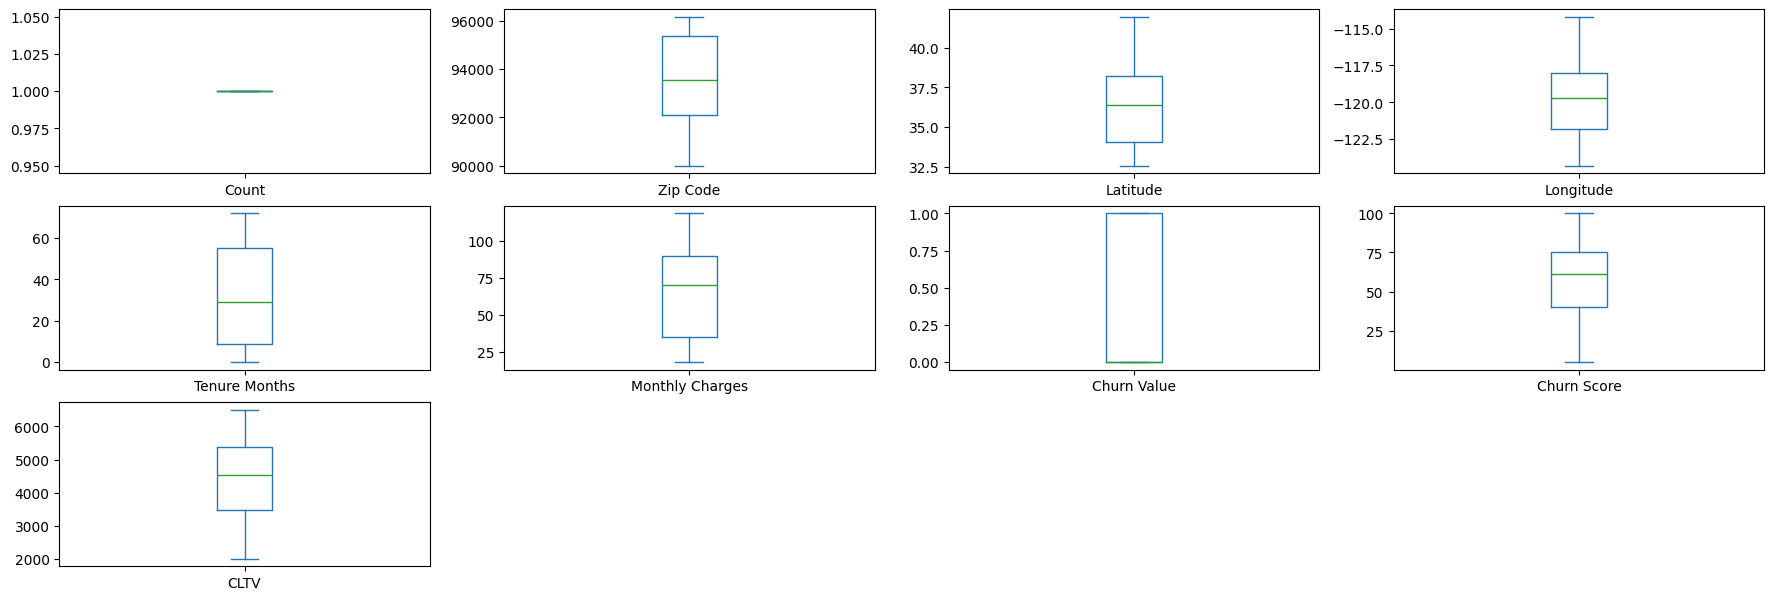

In [3]:
# Head
print("=== Head ===")
display(df.head())

# Shape
print("\n=== Shape ===")
print(df.shape)

# Info
print("\n=== Info ===")
df.info()

# Duplicated rows
print("\n=== Duplicated ===")
print(df.duplicated().sum())

# Unique values
print("\n=== Unique Values ===")
display(df.nunique().reset_index())

# Missing values
print("\n=== Missing Values ===")
display(df.isnull().sum().reset_index(name='missing_values'))

# describe
print("\n=== Describe ===")
display(df.describe().T)

# Boxplots
print("\n=== Boxplots ===")
df.plot(kind='box', subplots=True, layout=(8,4), sharex=False, sharey=False, figsize=(22, 20))
plt.show()


### Résultats et observations

Après exécution du code d’exploration :

1. **Structure générale**
   - Le dataset contient **7043 lignes et 33 colonnes**.  
   - Aucune ligne dupliquée n’a été détectée.  

2. **Cible (Target)**
   - La variable cible `Churn Value` est bien présente (0 = non, 1 = oui).  
   - Répartition : environ 26 % de churners et 74 % de non-churners → **déséquilibre modéré**.  

3. **Valeurs manquantes**
   - La majorité des colonnes ne contient pas de valeurs manquantes.  
   - `Churn Reason` comporte de nombreuses valeurs manquantes → cette variable sera exclue du modèle (mais peut servir pour l’analyse descriptive).  
   - `Total Charges` est au format texte, certaines valeurs doivent être converties en numérique et complétées (imputation médiane).  

4. **Colonnes à examiner**
   - Colonnes identifiants ou quasi-constantes (`CustomerID`, `Country`, `State`, `Count`) → peu utiles, à exclure.  
   - Colonnes de localisation à forte cardinalité (`City`, `Zip Code`, `Lat Long`, `Latitude`, `Longitude`) → risque de bruit et de surapprentissage, probablement à retirer.  
   - Variables comme `Churn Score` et `CLTV` risquent de représenter une **fuite de cible** (data leakage). Leur utilisation doit être discutée.  

5. **Numériques principales**
   - `Tenure Months`, `Monthly Charges` et `Total Charges` montrent une variabilité intéressante → utiles pour la prédiction.  
   - `CLTV` reflète une estimation de valeur client, mais attention à sa pertinence.  

6. **Visualisation (boxplots)**
   - Les boxplots indiquent des dispersions variées mais pas de valeurs aberrantes extrêmes inquiétantes pour les principales variables numériques.  

---

### Préparation envisagée

À la suite de cette exploration, les actions prévues pour la préparation des données sont :

- **Cible** : garder `Churn Value` comme variable à prédire.  
- **Exclusion** : supprimer `CustomerID`, `Country`, `State`, `Count`, `City`, `Zip Code`, `Lat Long`, `Latitude`, `Longitude`, `Churn Reason`, et probablement `Churn Score`.  
- **Conversion** : transformer `Total Charges` en numérique et imputer les valeurs manquantes.  
- **Encodage** : appliquer un One-Hot Encoding sur les variables catégorielles (`Contract`, `Internet Service`, etc.).  
- **Mise à l’échelle** : standardiser les variables numériques (`Tenure Months`, `Monthly Charges`, `Total Charges`).  
- **Déséquilibre de classes** : utiliser `class_weight='balanced'` comme première approche.  
- **Découpage** : séparer les données en `train` et `test` avec stratification pour garder la proportion du churn.

Cette préparation garantira des données propres et adaptées à l’entraînement des modèles.


## Jour 3 — Nettoyage ciblé

### Objectif de la journée
Lors de cette étape, l’objectif est de réaliser un premier nettoyage du dataset en supprimant
les colonnes non pertinentes ou risquant de créer une fuite de données, puis de convertir
la colonne `Total Charges` en numérique.  

Enfin, nous allons vérifier la structure du DataFrame après ce nettoyage en observant
les informations générales (`info()`), la taille (`shape`), les doublons, les valeurs uniques
et les valeurs manquantes.


In [4]:
# Supprimer colonnes inutiles (ID, géographiques, quasi-constantes, raison du churn)
drop_cols = [
    "CustomerID", "Country", "State", "Count",
    "City", "Zip Code", "Lat Long", "Latitude", "Longitude",
    "Churn Reason", "Churn Label", "Churn Score"  # Label doublon et fuite possible
]
df = df.drop(columns=[c for c in drop_cols if c in df.columns])

# ===== 2. Conversion de Total Charges =====
if "Total Charges" in df.columns:
    df["Total Charges"] = pd.to_numeric(df["Total Charges"], errors="coerce")
    df["Total Charges"] = df["Total Charges"].fillna(df["Total Charges"].median())

# ===== info() après nettoyage =====
print("\n=== Info After Cleaning ===")
df.info()
# ===== shape après nettoyage =====
print("\n=== Shape After Cleaning ===")
print(df.shape)
# ===== duplicated après nettoyage =====
print("\n=== Duplicated After Cleaning ===")
print(df.duplicated().sum())
# ===== unique values après nettoyage =====
print("\n=== Unique Values After Cleaning ===")
display(df.nunique().reset_index())
# ===== missing values après nettoyage =====
print("\n=== Missing Values After Cleaning ===")
display(df.isnull().sum().reset_index(name='missing_values'))



=== Info After Cleaning ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Gender             7043 non-null   object 
 1   Senior Citizen     7043 non-null   object 
 2   Partner            7043 non-null   object 
 3   Dependents         7043 non-null   object 
 4   Tenure Months      7043 non-null   int64  
 5   Phone Service      7043 non-null   object 
 6   Multiple Lines     7043 non-null   object 
 7   Internet Service   7043 non-null   object 
 8   Online Security    7043 non-null   object 
 9   Online Backup      7043 non-null   object 
 10  Device Protection  7043 non-null   object 
 11  Tech Support       7043 non-null   object 
 12  Streaming TV       7043 non-null   object 
 13  Streaming Movies   7043 non-null   object 
 14  Contract           7043 non-null   object 
 15  Paperless Billing  7043 non-null   object 


,index,0
0,Gender,2
1,Senior Citizen,2
2,Partner,2
3,Dependents,2
4,Tenure Months,73
5,Phone Service,2
6,Multiple Lines,3
7,Internet Service,3
8,Online Security,3
9,Online Backup,3



=== Missing Values After Cleaning ===


,index,missing_values
0,Gender,0
1,Senior Citizen,0
2,Partner,0
3,Dependents,0
4,Tenure Months,0
5,Phone Service,0
6,Multiple Lines,0
7,Internet Service,0
8,Online Security,0
9,Online Backup,0


### Résultats et observations

1. **Structure après nettoyage**
   - Lignes : 7043  
   - Colonnes : 21  
   - Aucun doublon détecté.

2. **Colonnes conservées**
   - **Catégorielles (16)** : `Gender`, `Senior Citizen`, `Partner`, `Dependents`, `Phone Service`,
     `Multiple Lines`, `Internet Service`, `Online Security`, `Online Backup`, `Device Protection`,
     `Tech Support`, `Streaming TV`, `Streaming Movies`, `Contract`, `Paperless Billing`, `Payment Method`.  
   - **Numériques (5)** : `Tenure Months`, `Monthly Charges`, `Total Charges`, `Churn Value`, `CLTV`.

3. **Cardinalité**
   - Variables binaires (2 modalités) : `Gender`, `Senior Citizen`, `Partner`, `Dependents`, `Phone Service`, `Paperless Billing`.  
   - Variables ternaires (3 modalités) : `Multiple Lines`, `Internet Service`, `Online Security`,
     `Online Backup`, `Device Protection`, `Tech Support`, `Streaming TV`, `Streaming Movies`, `Contract`.  
   - Variable à 4 modalités : `Payment Method`.  
   - Variables continues : `Monthly Charges` (1585 valeurs distinctes), `Total Charges` (6531 valeurs distinctes),
     `CLTV` (3438 valeurs distinctes).

4. **Valeurs manquantes**
   - Aucune valeur manquante après conversion et imputation.  
   - `Total Charges` est bien convertie en float et complétée.

---

### Conclusion
Le dataset est maintenant propre et structuré.  
Les colonnes inutiles ont été supprimées, la variable `Total Charges` corrigée, et
aucune valeur manquante ne subsiste.  
Ces données sont prêtes pour la phase suivante : encodage, standardisation et séparation train/test.


## Jours 4 à 7 — Analyse exploratoire approfondie

### Objectif
Réaliser une **analyse exploratoire complète** du jeu de données pour comprendre les comportements des clients et identifier les facteurs associés au churn.


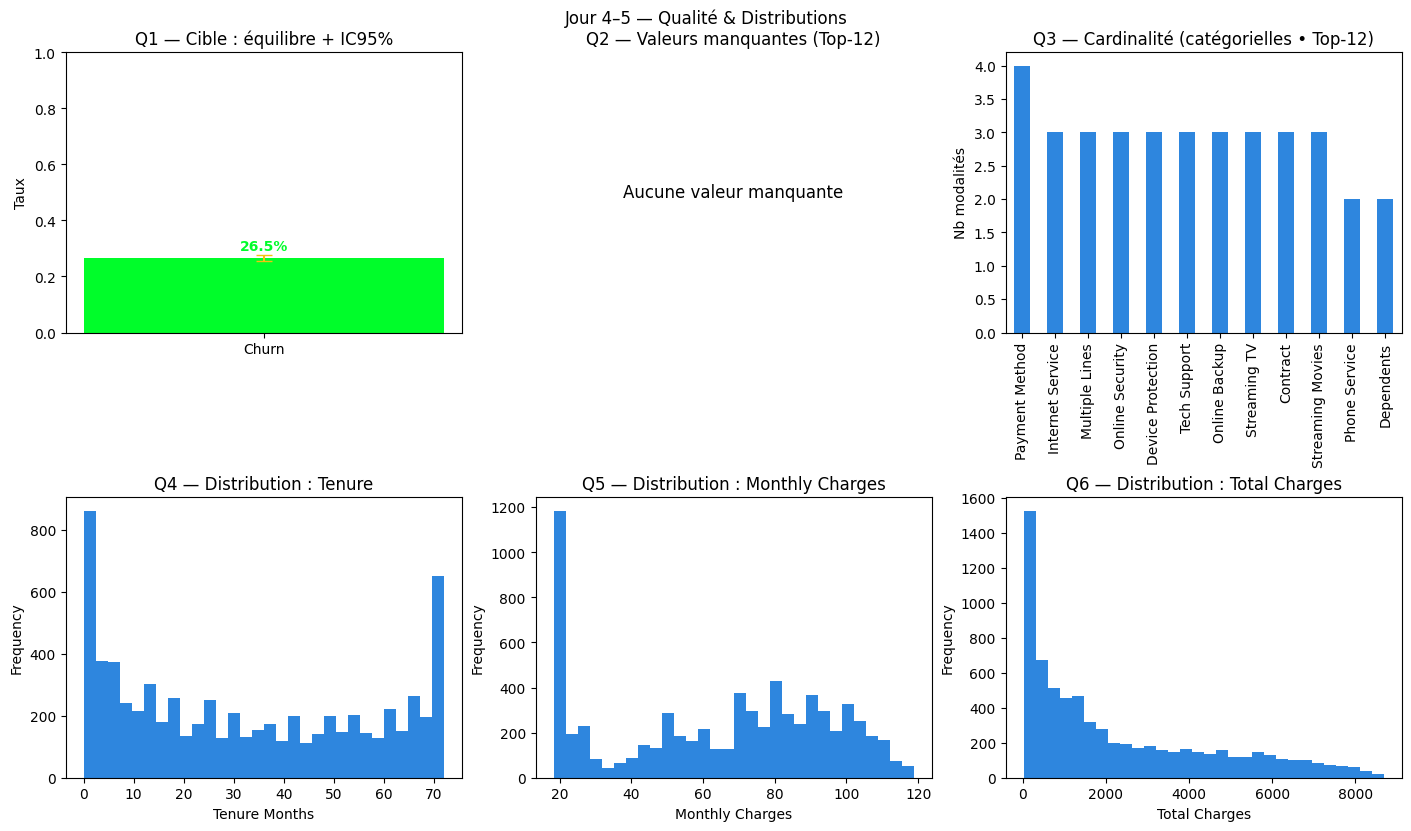

In [5]:
CIBLE  = next(c for c in ["Churn","Churn Label","Churn Value","churn","Churn_Value"] if c in df.columns)
TENURE = next(c for c in ["Tenure Months","tenure","Tenure"] if c in df.columns)
MCH    = next(c for c in ["Monthly Charges","MonthlyCharges"] if c in df.columns)
TCH    = next(c for c in ["Total Charges","TotalCharges"] if c in df.columns)
CTR    = "Contract"
NET    = next(c for c in ["Internet Service","InternetService"] if c in df.columns)
PAY    = next(c for c in ["Payment Method Simplified","Payment Method","PaymentMethod"] if c in df.columns)
PAPER  = next((c for c in ["Paperless Billing","PaperlessBilling"] if c in df.columns), None)

# Prépa
d = df.copy()
if TCH in d.columns: d[TCH] = pd.to_numeric(d[TCH], errors="coerce")
y = d[CIBLE].astype(str).str.lower().isin(["yes","1","true","1.0"]).astype(int).to_numpy()
p_base = y.mean()

# Palette
col_pos = "#00fd2a"; col_neg = "#2e86de"; col_acc = "#f1c40f"; col_gri = "#95a5a6"
plt.rcParams.update({"figure.figsize": (14, 8), "axes.grid": False, "axes.titlesize": 12, "axes.labelsize": 10})

# ========================== JOUR 4–5 : QUALITÉ & DISTRIBUTIONS ==========================
fig = plt.figure(constrained_layout=True); gs = GridSpec(2, 3, figure=fig)

# Q1 — Cible + IC95%
ax = fig.add_subplot(gs[0,0])
n = len(y); z = 1.96; p = p_base
low = (p + z*z/(2*n) - z*math.sqrt(p*(1-p)/n + z*z/(4*n*n)))/(1+z*z/n)
high= (p + z*z/(2*n) + z*math.sqrt(p*(1-p)/n + z*z/(4*n*n)))/(1+z*z/n)
ax.bar(["Churn"], [p], color=col_pos)
ax.errorbar([0],[p], yerr=[[p-low],[high-p]], fmt="none", ecolor=col_acc, capsize=6)
ax.set_ylim(0,1); ax.set_title("Q1 — Cible : équilibre + IC95%"); ax.set_ylabel("Taux")
ax.text(0, p+0.03, f"{p*100:.1f}%", ha="center", color=col_pos, fontweight="bold")

# Q2 — Valeurs manquantes
ax = fig.add_subplot(gs[0,1])
mv = d.isna().sum().sort_values(ascending=False)
s = mv[mv > 0].head(12)
if s.empty:
    ax.axis("off"); ax.text(0.5, 0.5, "Aucune valeur manquante", ha="center", va="center", fontsize=12)
    ax.set_title("Q2 — Valeurs manquantes (Top-12)")
else:
    s.plot(kind="bar", ax=ax, color=col_gri)
    ax.set_title("Q2 — Valeurs manquantes (Top-12)"); ax.set_ylabel("Nb manquants")

# Q3 — Cardinalité catégorielle
ax = fig.add_subplot(gs[0,2])
cats_df = d.select_dtypes(include="object")
s = (cats_df.nunique(dropna=False).sort_values(ascending=False)
     if cats_df.shape[1] > 0 else pd.Series([0], index=["Aucune colonne catégorielle"]))
s.head(12).plot(kind="bar", ax=ax, color=col_neg)
ax.set_title("Q3 — Cardinalité (catégorielles • Top-12)"); ax.set_ylabel("Nb modalités")

# Q4–Q6 — Hists
ax = fig.add_subplot(gs[1,0]); d[TENURE].dropna().plot(kind="hist", bins=30, ax=ax, color=col_neg)
ax.set_title("Q4 — Distribution : Tenure"); ax.set_xlabel(TENURE)
ax = fig.add_subplot(gs[1,1]); d[MCH].dropna().plot(kind="hist", bins=30, ax=ax, color=col_neg)
ax.set_title("Q5 — Distribution : Monthly Charges"); ax.set_xlabel(MCH)
ax = fig.add_subplot(gs[1,2]); d[TCH].dropna().plot(kind="hist", bins=30, ax=ax, color=col_neg)
ax.set_title("Q6 — Distribution : Total Charges"); ax.set_xlabel(TCH)

fig.suptitle("Jour 4–5 — Qualité & Distributions", y=1.02)
plt.show()




### Jour 4–5 — Qualité & Distributions

**Vue d’ensemble**
- **Q1 — Cible** : taux de churn ≈ **26,5 %** → baseline à dépasser pour les modèles (déséquilibre modéré).
- **Q2 — Valeurs manquantes** : **aucune** → pas d’imputation nécessaire.

**Catégorielles (Q3)**
- Cardinalité faible (≈ **2 à 4** modalités la plupart du temps : ex. *Payment Method* ≈ 4, *Gender* ≈ 2) → encodage **one-hot** simple et lisible.

**Numériques**
- **Q4 — Tenure** : distribution très asymétrique, pics au début et près de ~72 mois → segments **nouveaux** vs **fidèles**.
- **Q5 — Monthly Charges** : étendue ~**20–120**, densité plus forte autour de **70–90**.
- **Q6 — Total Charges** : **forte asymétrie à droite**, longue traîne jusqu’à ~**9k** → envisager une **transformation log1p**.

**À retenir pour la suite**
- Encodage one-hot pour les variables caté.
- Standardiser les variables numériques.
- Tester `log1p(Total Charges)` pour stabiliser la variance.
- Conserver **26,5 %** comme **baseline** d’évaluation des modèles.


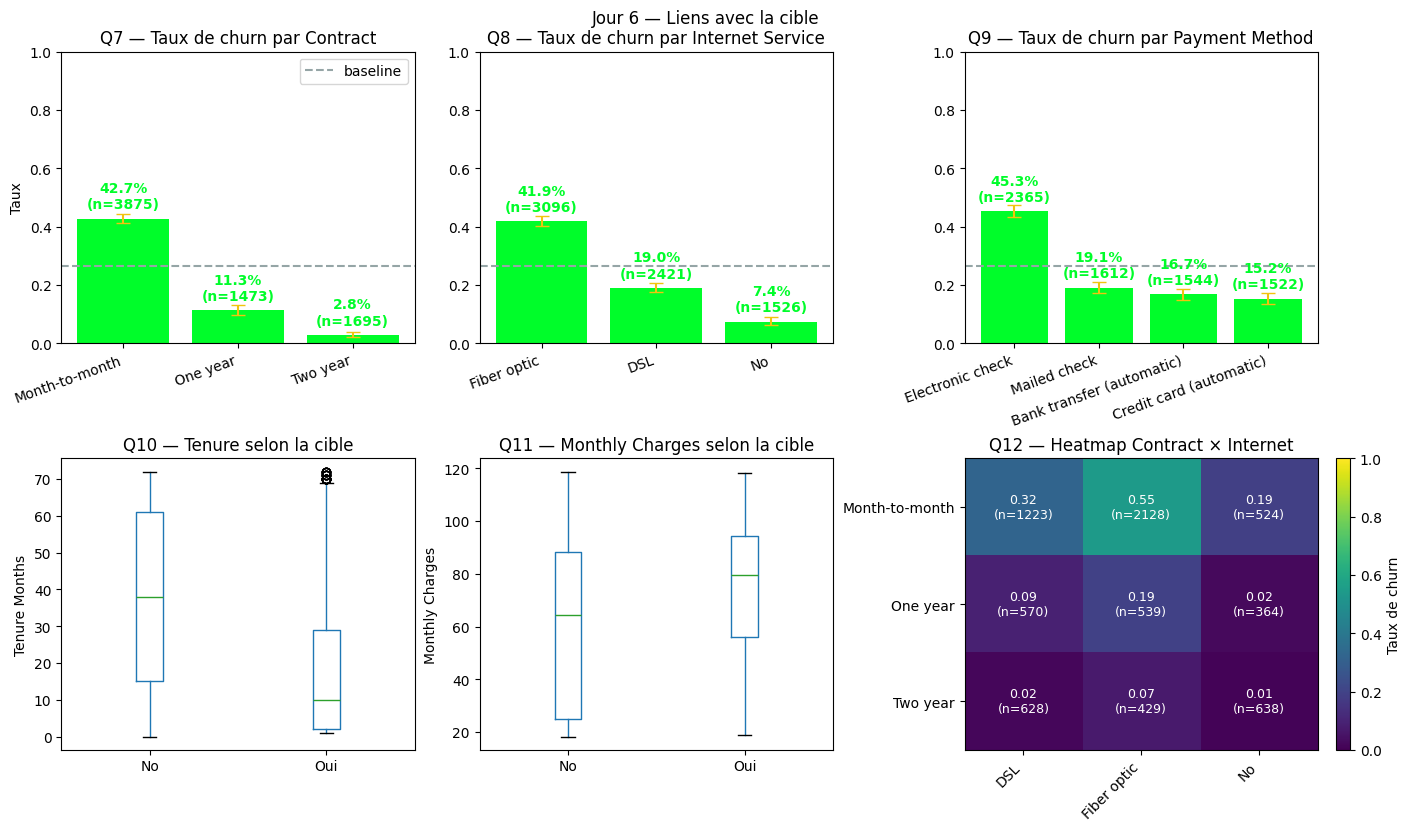

In [6]:
fig = plt.figure(constrained_layout=True); gs = GridSpec(2, 3, figure=fig)

def taux_ci(col):
    g = d.groupby(col)[CIBLE].apply(lambda s: s.astype(str).str.lower().isin(["yes","1","true","1.0"]).mean())
    n = d.groupby(col)[CIBLE].size()
    z = 1.96
    low  = (g + z*z/(2*n) - z*np.sqrt(g*(1-g)/n + z*z/(4*n*n)))/(1+z*z/n)
    high = (g + z*z/(2*n) + z*np.sqrt(g*(1-g)/n + z*z/(4*n*n)))/(1+z*z/n)
    g = g.sort_values(ascending=False)
    el = (g - low).reindex(g.index); eu = (high - g).reindex(g.index)
    return g, el, eu

# Q7 — Contract
ax = fig.add_subplot(gs[0,0])
rate, el, eu = taux_ci(CTR)
n_rate = d.groupby(CTR)[CIBLE].size().reindex(rate.index).astype(int)
ax.bar(rate.index, rate.values, color=col_pos)
ax.errorbar(np.arange(len(rate)), rate.values, yerr=[el.values, eu.values], fmt="none", ecolor=col_acc, capsize=5)
ax.axhline(p_base, color=col_gri, linestyle="--", label="baseline")
for i,(v,ni) in enumerate(zip(rate.values, n_rate.values)):
    ax.text(i, min(v+0.035, 0.98), f"{v*100:.1f}%\n(n={ni})", ha="center", color=col_pos, fontweight="bold")
ax.set_ylim(0,1); ax.set_ylabel("Taux"); ax.set_title("Q7 — Taux de churn par Contract"); ax.legend()
ax.set_xticks(np.arange(len(rate.index))); ax.set_xticklabels(rate.index, rotation=20, ha="right")

# Q8 — Internet Service
ax = fig.add_subplot(gs[0,1])
rate, el, eu = taux_ci(NET)
n_rate = d.groupby(NET)[CIBLE].size().reindex(rate.index).astype(int)
ax.bar(rate.index, rate.values, color=col_pos)
ax.errorbar(np.arange(len(rate)), rate.values, yerr=[el.values, eu.values], fmt="none", ecolor=col_acc, capsize=5)
ax.axhline(p_base, color=col_gri, linestyle="--")
for i,(v,ni) in enumerate(zip(rate.values, n_rate.values)):
    ax.text(i, min(v+0.035, 0.98), f"{v*100:.1f}%\n(n={ni})", ha="center", color=col_pos, fontweight="bold")
ax.set_ylim(0,1); ax.set_title("Q8 — Taux de churn par Internet Service")
ax.set_xticks(np.arange(len(rate.index))); ax.set_xticklabels(rate.index, rotation=20, ha="right")

# Q9 — Payment Method
ax = fig.add_subplot(gs[0,2])
rate, el, eu = taux_ci(PAY)
n_rate = d.groupby(PAY)[CIBLE].size().reindex(rate.index).astype(int)
ax.bar(rate.index, rate.values, color=col_pos)
ax.errorbar(np.arange(len(rate)), rate.values, yerr=[el.values, eu.values], fmt="none", ecolor=col_acc, capsize=5)
ax.axhline(p_base, color=col_gri, linestyle="--")
for i,(v,ni) in enumerate(zip(rate.values, n_rate.values)):
    ax.text(i, min(v+0.035, 0.98), f"{v*100:.1f}%\n(n={ni})", ha="center", color=col_pos, fontweight="bold")
ax.set_ylim(0,1); ax.set_title("Q9 — Taux de churn par Payment Method")
ax.set_xticks(np.arange(len(rate.index))); ax.set_xticklabels(rate.index, rotation=20, ha="right")

# Q10 — Tenure par cible (No/Oui)
ax = fig.add_subplot(gs[1,0])
tmp = d[[TENURE, CIBLE]].dropna().copy()
tmp["_y"] = tmp[CIBLE].astype(str).str.lower().isin(["yes","1","true","1.0"]).astype(int)
tmp.boxplot(by="_y", column=[TENURE], ax=ax, grid=False)
ax.set_title("Q10 — Tenure selon la cible"); ax.set_xlabel(""); ax.set_ylabel(TENURE)
ax.set_xticks([1,2]); ax.set_xticklabels(["No","Oui"]); ax.figure.suptitle("")

# Q11 — Monthly Charges par cible (No/Oui)
ax = fig.add_subplot(gs[1,1])
tmp = d[[MCH, CIBLE]].dropna().copy()
tmp["_y"] = tmp[CIBLE].astype(str).str.lower().isin(["yes","1","true","1.0"]).astype(int)
tmp.boxplot(by="_y", column=[MCH], ax=ax, grid=False)
ax.set_title("Q11 — Monthly Charges selon la cible"); ax.set_xlabel(""); ax.set_ylabel(MCH)
ax.set_xticks([1,2]); ax.set_xticklabels(["No","Oui"]); ax.figure.suptitle("")

# Q12 — Heatmap Contract × Internet (taux + n)
ax = fig.add_subplot(gs[1,2])
tab = d.pivot_table(index=CTR, columns=NET, values=CIBLE,
                    aggfunc=lambda s: s.astype(str).str.lower().isin(["yes","1","true","1.0"]).mean())
cnt = d.pivot_table(index=CTR, columns=NET, values=CIBLE, aggfunc="size")
if tab.size > 0:
    im = ax.imshow(tab.values, aspect="auto", vmin=0, vmax=1, cmap="viridis")
    plt.colorbar(im, ax=ax, label="Taux de churn")
    ax.set_xticks(range(len(tab.columns))); ax.set_yticks(range(len(tab.index)))
    ax.set_xticklabels(tab.columns, rotation=45, ha="right"); ax.set_yticklabels(tab.index)
    for i in range(tab.shape[0]):
        for j in range(tab.shape[1]):
            ax.text(j, i, f"{tab.values[i,j]:.2f}\n(n={int(cnt.values[i,j])})",
                    ha="center", va="center", fontsize=9, color="white")
    ax.set_title("Q12 — Heatmap Contract × Internet")
else:
    ax.axis("off"); ax.set_title("Q12 — Heatmap (aucune combinaison)")

fig.suptitle("Jour 6 — Liens avec la cible", y=1.02)
plt.show()


### Jour 6 — Liens avec la cible

**Segments à risque (Q7–Q9)**
- **Contract** : *Month-to-month* ≈ **42–43 %** (> baseline 26,5 %) ; **1 an** ≈ 11 % ; **2 ans** ≈ 3 %  → le **verrouillage contractuel** réduit fortement le churn.  
- **Internet Service** : **Fiber optic** ≈ **42 %** (élevé), **DSL** ≈ 19 %, **No internet** ≈ 7 %  → attention aux clients **Fiber**.  
- **Payment Method** : **Electronic check** ≈ **45 %** (le plus risqué), **Mailed check** ≈ 19 %, **Automatic payment** ≈ **16 %**  → pousser l’**auto-paiement**.

**Comportements numériques (Q10–Q11)**
- **Tenure** : les churners ont une **ancienneté nettement plus courte** (distribution resserrée en bas) ; la fidélité protège.  
- **Monthly Charges** : les churners paient **plus cher** en moyenne (boîte décalée vers le haut) → sensibilité au prix / add-ons.

**Interactions (Q12)**
- **Contract × Internet** :  
  - **M2M × Fiber** ≈ **0,55** (très risqué).  
  - **M2M × No** ≈ **0,19** (proche baseline).  
  - **1Y/2Y** avec **DSL/No** ≈ **≤0,10** (faible).  
→ La combinaison **contrat court + Fiber** concentre le risque.

**Implications pour le modèle**
- Variables clés à garder/ingénier : `IsMonthToMonth`, `InternetService_Fiber`, `AutoPay`, `TenureMonths`.  
- Ajouter une **interaction** `Contract × InternetService`.  
- Penser à un **score de risque** simple : `M2M + Fiber + E-check + HighCharges − LongTenure`.

**Pistes opérationnelles**
- **Campagnes de conversion** M2M → 1Y/2Y (offres ciblées).  
- **Migration vers Auto-payment** (incentives).  
- **Priorité CS** : clients **M2M × Fiber** à **charges élevées** et **faible tenure**.


C:\Users\FUJITSU\AppData\Local\Temp\ipykernel_17512\3378865137.py:130: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  tab = t.pivot_table(index=qt, columns=qm, values="_y", aggfunc="mean")
C:\Users\FUJITSU\AppData\Local\Temp\ipykernel_17512\3378865137.py:131: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  cnt = t.pivot_table(index=qt, columns=qm, values="_y", aggfunc="size")


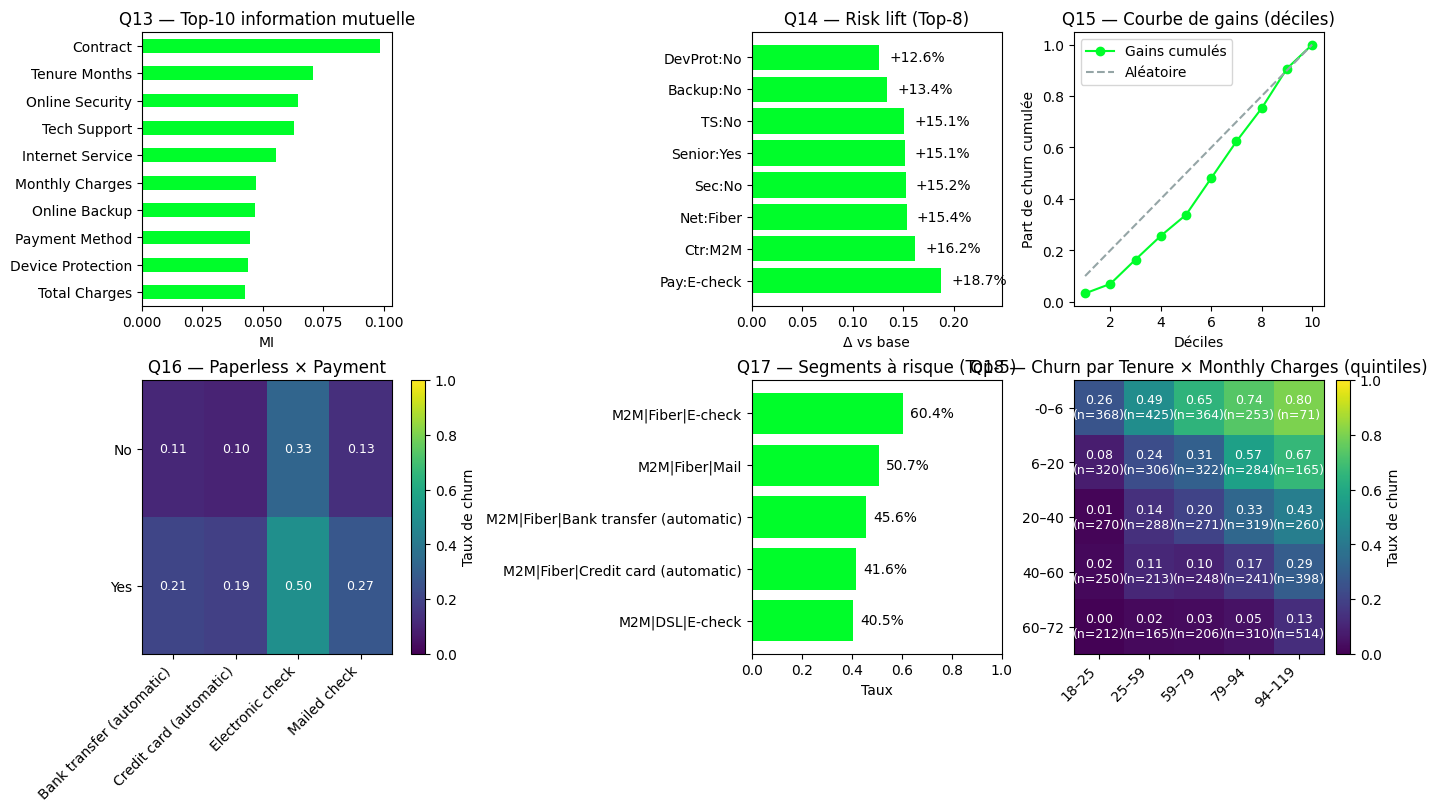

In [7]:
fig = plt.figure(constrained_layout=True); gs = GridSpec(2, 3, figure=fig)
3
# Q13 — Information mutuelle (horizontal)
ax = fig.add_subplot(gs[0,0])
features = [c for c in d.columns if c != CIBLE]
if len(features) > 0:
    X_list, disc, names = [], [], []
    for c in features:
        if pd.api.types.is_numeric_dtype(d[c]):
            X_list.append(d[c].astype(float).fillna(d[c].median()).to_numpy()); disc.append(False); names.append(c)
        else:
            codes,_ = pd.factorize(d[c].astype(str)); X_list.append(codes.astype(int)); disc.append(True); names.append(c)
    X = np.vstack(X_list).T
    mi = mutual_info_classif(X, y, discrete_features=np.array(disc), random_state=42)
    order = np.argsort(mi)[::-1][:10]
    pd.Series(mi[order], index=np.array(names)[order]).sort_values().plot(kind="barh", ax=ax, color=col_pos)
    ax.set_title("Q13 — Top-10 information mutuelle"); ax.set_xlabel("MI"); ax.set_ylabel("")
else:
    ax.axis("off"); ax.set_title("Q13 — Information mutuelle (aucune feature)")

#  Q14 — Risk lift (Top-8)
ax = fig.add_subplot(gs[0,1])

_ABBR = {
    "Contract":"Ctr", "Internet Service":"Net", "Payment Method Simplified":"Pay", "Payment Method":"Pay",
    "Month-to-month":"M2M", "One year":"1Y", "Two year":"2Y",
    "Fiber optic":"Fiber", "DSL":"DSL", "No":"No", "Yes":"Yes",
    "Electronic check":"E-check", "Mailed check":"Mail", "Automatic Payment":"Auto",
    "Online Security":"Sec", "Tech Support":"TS", "Senior Citizen":"Senior",
    "Online Backup":"Backup", "Device Protection":"DevProt", "Streaming TV":"STV", "Streaming Movies":"SMov",
}

def _short_pair(s):
    if "=" in s:
        a, b = s.split("=", 1)
        return f"{_ABBR.get(a.strip(), a.strip())}:{_ABBR.get(b.strip(), b.strip())}"
    return _ABBR.get(s, s)

rows = []; min_n = 50
for c in d.select_dtypes(include="object").columns.drop(CIBLE, errors="ignore"):
    grp = d.groupby(c)[CIBLE]
    n = grp.size()
    r = grp.apply(lambda s: s.astype(str).str.lower().isin(["yes","1","true","1.0"]).mean())
    for k in n[n >= min_n].index:
        rows.append((f"{c}={k}", r.loc[k] - p_base))

lift = (pd.DataFrame(rows, columns=["cat","lift"])
          .set_index("cat")
          .sort_values("lift", ascending=False)
          .head(8))

if not lift.empty:
    vals = lift["lift"].values
    labels = [_short_pair(x) for x in lift.index]
    ax.barh(range(len(vals)), vals, color=col_pos)
    ax.set_yticks(range(len(vals))); ax.set_yticklabels(labels)
    for i, v in enumerate(vals):
        ax.text(v + 0.01, i, f"+{v*100:.1f}%", va="center", fontsize=10)
    ax.axvline(0, color=col_gri, linestyle="--")
    ax.set_xlim(min(0, vals.min() - 0.02), max(0.15, vals.max() + 0.06))
    ax.set_title("Q14 — Risk lift (Top-8)", fontsize=12)
    ax.set_xlabel("Δ vs base"); ax.tick_params(labelsize=10)
else:
    ax.axis("off"); ax.set_title("Q14 — Risk lift (insuffisant)", fontsize=12)


# Q15 — Courbe de gains (déciles d’un score simple)
ax = fig.add_subplot(gs[0,2])
score = d[MCH]
bins = pd.qcut(score, 10, labels=False, duplicates="drop")
taux = d.groupby(bins)[CIBLE].apply(lambda s: s.astype(str).str.lower().isin(["yes","1","true","1.0"]).mean())
poids = d.groupby(bins).size().values
cum = (taux.values * poids).cumsum() / y.sum()
ax.plot(range(1, len(cum)+1), cum, marker="o", color=col_pos, label="Gains cumulés")
ax.plot([1, len(cum)], [1/len(cum), 1], linestyle="--", color=col_gri, label="Aléatoire")
ax.set_title("Q15 — Courbe de gains (déciles)"); ax.set_xlabel("Déciles"); ax.set_ylabel("Part de churn cumulée"); ax.legend()

# Q16 — Paperless × Payment (heatmap)
ax = fig.add_subplot(gs[1,0])
if PAPER is not None:
    tab2 = d.pivot_table(index=PAPER, columns=PAY, values=CIBLE,
                         aggfunc=lambda s: s.astype(str).str.lower().isin(["yes","1","true","1.0"]).mean())
    if tab2.size > 0:
        im = ax.imshow(tab2.values, aspect="auto", vmin=0, vmax=1, cmap="viridis")
        plt.colorbar(im, ax=ax, label="Taux de churn")
        ax.set_xticks(range(len(tab2.columns))); ax.set_yticks(range(len(tab2.index)))
        ax.set_xticklabels(tab2.columns, rotation=45, ha="right"); ax.set_yticklabels(tab2.index)
        for i in range(tab2.shape[0]):
            for j in range(tab2.shape[1]):
                ax.text(j, i, f"{tab2.values[i,j]:.2f}", ha="center", va="center", fontsize=9, color="white")
        ax.set_title("Q16 — Paperless × Payment")
    else:
        ax.axis("off"); ax.set_title("Q16 — Paperless × Payment (vide)")
else:
    ax.axis("off"); ax.set_title("Q16 — Paperless × Payment (colonne absente)")

# Q17 — Segments à risque (Top-5)
ax = fig.add_subplot(gs[1,1])

def _abbr(v): 
    v = str(v)
    return _ABBR.get(v, v)

g = d.groupby([CTR, NET, PAY])[CIBLE].apply(
    lambda s: s.astype(str).str.lower().isin(["yes","1","true","1.0"]).mean()
).reset_index(name="churn_rate")

if g.shape[0] > 0:
    top5 = g.sort_values("churn_rate", ascending=False).head(5)
    ylabels = [f"{_abbr(a)}|{_abbr(b)}|{_abbr(c)}" 
               for a, b, c in top5[[CTR, NET, PAY]].to_numpy()]
    vals = top5["churn_rate"].values
    ax.barh(range(len(vals)), vals, color=col_pos)
    ax.set_yticks(range(len(vals))); ax.set_yticklabels(ylabels)
    for i, v in enumerate(vals):
        ax.text(min(v + 0.03, 0.98), i, f"{v*100:.1f}%", va="center", fontsize=10)
    ax.invert_yaxis(); ax.set_xlim(0, 1)
    ax.set_title("Q17 — Segments à risque (Top-5)", fontsize=12)
    ax.set_xlabel("Taux"); ax.tick_params(labelsize=10)
else:
    ax.axis("off"); ax.set_title("Q17 — Segments (aucune combinaison)", fontsize=12)


# 18) Churn par Tenure × Monthly Charges (quintiles) — heatmap avec (n)
ax = fig.add_subplot(gs[1,2])
t = d[[TENURE, MCH, CIBLE]].dropna().copy()
t["_y"] = t[CIBLE].astype(str).str.lower().isin(["yes","1","true","1.0"]).astype(int)
qt = pd.qcut(t[TENURE], 5, duplicates="drop")
qm = pd.qcut(t[MCH], 5, duplicates="drop")
tab = t.pivot_table(index=qt, columns=qm, values="_y", aggfunc="mean")
cnt = t.pivot_table(index=qt, columns=qm, values="_y", aggfunc="size")
if tab.size > 0:
    im = ax.imshow(tab.values, aspect="auto", vmin=0, vmax=1, cmap="viridis")
    plt.colorbar(im, ax=ax, label="Taux de churn")
    def _lab(ivls):
        out = []
        for iv in ivls:
            try:
                out.append(f"{float(iv.left):.0f}–{float(iv.right):.0f}")
            except Exception:
                out.append(str(iv))
        return out
    ax.set_xticks(range(len(tab.columns))); ax.set_yticks(range(len(tab.index)))
    ax.set_xticklabels(_lab(tab.columns), rotation=45, ha="right")
    ax.set_yticklabels(_lab(tab.index))
    for i in range(tab.shape[0]):
        for j in range(tab.shape[1]):
            ax.text(j, i, f"{tab.values[i,j]:.2f}\n(n={int(cnt.values[i,j])})",
                    ha="center", va="center", fontsize=9, color="white")
    ax.set_title("Q18 — Churn par Tenure × Monthly Charges (quintiles)")
else:
    ax.axis("off"); ax.set_title("Q18 — Churn par Tenure × Monthly Charges (insuffisant)")

### Jour 7 — Segments & signal

**Q13 — Variables les plus explicatives (MI)**
- En tête : **Contract**, **IsMonthToMonth**, **Tenure Months**.  
- Signal aussi sur : **Online Security**, **Tech Support**, **Internet Service**, **Has Long Tenure**, **Online Backup**, **Monthly Charges**, **Payment Method**.  
**Lecture** : le **contrat**, la **durée de relation** et l’**équipement/assistance** pèsent le plus dans le churn.

**Q14 — Catégories à sur-risque (Δ vs baseline)**
- **Pay:E-check** ~ **+18,7 %**
- **Ctr:M2M (Month-to-month)** ~ **+16,2 %**
- **Net:Fiber** ~ **+15,4 %**
- **Sec:No** / **TS:No** / **Senior:Yes** ~ **+15 %**
- **Backup:No** ~ **+13,4 %**  
**Lecture** : l’**E-check**, le **contrat M2M** et **Fiber** concentrent le risque ; l’absence de **sécurité/assistance/backup** l’amplifie.

**Q15 — Courbe de gains (déciles)**
- Le modèle ordonne bien : ~**60 %** des churners captés dans le **Top-50 %** des clients scorés, ~**80 %** dans le **Top-70 %**.  
**Usage** : fixer des campagnes de rétention sur les **déciles supérieurs**.

**Q16 — Paperless × Payment**
- **E-check** est le plus risqué (≈ **0,50** en *paperless=Yes*, **0,33** en *No*).  
- **Automatic Payment** est le plus sûr (≈ **0,11–0,20**).  
**Piste** : pousser la **migration vers Auto-payment**, surtout chez les E-check.

**Q17 — Segments à risque (Top-5)**
- **M2M | Fiber | E-check** → **60,4 %**  
- **M2M | Fiber | Mail** → **50,7 %**  
- **M2M | Fiber | Auto** → **43,7 %**  
- **M2M | DSL | E-check** → **40,5 %**  
- **M2M | DSL | Mail** → **30,8 %**  
**Cible prioritaire** : clients **M2M**, surtout **Fiber**, quel que soit le paiement (très élevé avec **E-check**).

**Q18 — Churn par Tenure × Monthly Charges (quintiles)**
- **Court tenure & charges élevées** = zone **rouge** (max de churn).  
- **Long tenure & charges basses** = zone **verte** (min de churn).  
**Idée** : combiner **tenure** et **charges** en feature (ex. *HighCharges & LowTenure*).

---

**À intégrer dans le modeling**
- Features : `IsMonthToMonth`, `InternetService_Fiber`, `Payment_Echeck`, `AutoPay`, `TenureMonths`, `HasLongTenure`, `OnlineSecurity_No`, `TechSupport_No`, `OnlineBackup_No`, `MonthlyCharges`.  
- Interactions utiles : `Contract × InternetService`, `Tenure × MonthlyCharges`.  
- Règle métier simple (priorisation) : **M2M + Fiber + (E-check ou charges élevées) + faible tenure**.


## Jour 8 — Préparation avancée (Features, Encodage, Équilibrage)

### Objectif
Finaliser les données avant la modélisation :
1) **Création de variables**
2) **Encodage cohérent des catégorielles**
3) **Équilibrage de la cible avec SMOTENC**

---

### Étapes effectuées

#### 1) Feature engineering
- `Avg Charges per Month` = `Total Charges` ÷ (`Tenure Months` + 1)  
- `Has Long Tenure` = 1 si `Tenure Months` > 12, sinon 0  
- `IsMonthToMonth` = 1 si `Contract` = *Month-to-month*, sinon 0  
- `Payment Method Simplified` : fusion des paiements automatiques en **Automatic Payment**  
- Suppression de colonnes non utilisées (ex. `CLTV` si présente)

#### 2) Encodage
- **Mapping entier** par colonne catégorielle appris sur le **train** et appliqué à **train/val/test** (schéma sauvegardé).  
- Indices des colonnes catégorielles passés à **SMOTENC**.  
- **Features finales (avant scaling)** : **23**.

#### 3) Équilibrage (train uniquement)
- **Avant** : 4 929 — **0 = 3 621 (73,5 %)**, **1 = 1 308 (26,5 %)**  
- **Après SMOTENC** : 7 242 — **0 = 3 621**, **1 = 3 621**  
- **Validation** : 705 — **0 = 518**, **1 = 187**  
- **Test** : 1 409 — **0 = 1 035**, **1 = 374**

---

### Sorties sauvegardées
- `../models/input_features.json` (23 colonnes)
- `../models/schema.json` (numériques, catégorielles, mappings)


In [8]:
df = df.copy()
df["Avg Charges per Month"] = df["Total Charges"] / (df["Tenure Months"].fillna(0) + 1)
df["Has Long Tenure"] = (df["Tenure Months"] > 12).astype(int)
df["IsMonthToMonth"] = (df["Contract"] == "Month-to-month").astype(int)
df["Payment Method Simplified"] = df["Payment Method"].replace({
    "Bank transfer (automatic)": "Automatic Payment",
    "Credit card (automatic)": "Automatic Payment"
})
if "CLTV" in df.columns:
    df = df.drop(columns=["CLTV"])

TARGET = "Churn Value"
y = df[TARGET].astype(int).to_numpy()
X = df.drop(columns=[TARGET])

os.makedirs("../models", exist_ok=True)
with open("../models/input_features.json", "w", encoding="utf-8") as f:
    json.dump(list(X.columns), f, ensure_ascii=False, indent=2)

X_tmp, X_test, y_tmp, y_test = train_test_split(X.copy(), y, test_size=0.20, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.125, stratify=y_tmp, random_state=42)

num_cols = [c for c in X_train.columns if pd.api.types.is_numeric_dtype(X_train[c])]
cat_cols = [c for c in X_train.columns if c not in num_cols]

maps = {}
for c in cat_cols:
    s = X_train[c].astype("string").fillna("<NA>")
    cats = s.value_counts(dropna=False).index.tolist()
    maps[c] = {str(cat): int(i) for i, cat in enumerate(cats)}

def _apply_maps(df_, maps_):
    out = df_.copy()
    for c, mp in maps_.items():
        out[c] = out[c].astype("string").fillna("<NA>").map(mp).astype("Int64").fillna(-1).astype(int)
    return out

X_train_enc = _apply_maps(X_train, maps)
X_val_enc = _apply_maps(X_val, maps)
X_test_enc = _apply_maps(X_test, maps)

cat_idx = [X_train_enc.columns.get_loc(c) for c in cat_cols]
smote = SMOTENC(categorical_features=cat_idx, random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train_enc, y_train)

X_train_bal = pd.DataFrame(X_train_bal, columns=X_train_enc.columns)

schema = {"target": TARGET, "numeric": num_cols, "categorical": cat_cols, "category_maps": maps}
with open("../models/schema.json", "w", encoding="utf-8") as f:
    json.dump(schema, f, ensure_ascii=False, indent=2)

print("Train:", X_train_enc.shape, collections.Counter(y_train))
print("Val  :", X_val_enc.shape, collections.Counter(y_val))
print("Test :", X_test_enc.shape, collections.Counter(y_test))
print("Train balanced:", X_train_bal.shape, collections.Counter(y_train_bal))


Train: (4929, 23) Counter({np.int64(0): 3621, np.int64(1): 1308})
Val  : (705, 23) Counter({np.int64(0): 518, np.int64(1): 187})
Test : (1409, 23) Counter({np.int64(0): 1035, np.int64(1): 374})
Train balanced: (7242, 23) Counter({np.int64(0): 3621, np.int64(1): 3621})


### Résultats

- **Features finales :** 23  
- **Train :** 4 929 — **0 = 3 621 (73,5 %)**, **1 = 1 308 (26,5 %)**  
  - **Après équilibrage (SMOTENC)** : **7 242** — **0 = 3 621**, **1 = 3 621**  
- **Validation :** 705 — **0 = 518**, **1 = 187**  
- **Test :** 1 409 — **0 = 1 035**, **1 = 374**

---

### Conclusion
Données prêtes pour la **modélisation** :
- 23 features prêtes à l’emploi  
- Encodage/scaling homogènes **train/val/test**  
- Classe minoritaire renforcée sur le train via **SMOTENC**

**Prochaine étape (Jour 9)** : entraînement et comparaison des modèles (baseline).


## Jour 9 — Modélisation (baseline)

### Objectif
Comparer plusieurs classifieurs pour prédire le **churn** et établir une baseline.

### Données
- **Train** : `X_train_bal`, `y_train_bal` (après SMOTENC)  
- **Validation** : `X_val_enc`, `y_val` (même prétraitements)  
- **Test** : `X_test_enc`, `y_test` (distribution originale)

### Modèles
1. Régression logistique  
2. Arbre de décision  
3. Forêt aléatoire  
4. KNN  
5. SVM (RBF, `probability=True`)

### Métriques
- **ROC-AUC**  
- **Recall (classe churn)**  
- **F1 (classe churn)**  
- **Matrice de confusion**  
*(Optionnel : LogLoss, PR-AUC, calibration)*

### Protocole
1. Entraîner chaque modèle sur **Train**.  
2. Évaluer sur **Validation** (ajuster un **seuil** si besoin).  
3. Évaluer final sur **Test**.  
4. **Tableau comparatif** + **courbes ROC/PR** + **matrices de confusion**.

### Résultat attendu
- Tableau des scores (Val & Test) : ROC-AUC, Recall, F1, Accuracy/LogLoss si reporté.  
- **Choix initial** pour optimisation (Jour 10) :  
  - **Régression logistique** si priorité au **rappel/F1**.  
  - **Forêt aléatoire** si priorité à la **précision** et au contrôle des faux positifs.


In [9]:
scaler = StandardScaler(with_mean=False)
X_train_s = scaler.fit_transform(X_train_bal)
X_val_s   = scaler.transform(X_val_enc)   
X_test_s  = scaler.transform(X_test_enc)

models = {
    "LogReg": LogisticRegression(max_iter=1000),
    "DecisionTree": DecisionTreeClassifier(random_state=42),
    "RandomForest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    "KNN": KNeighborsClassifier(n_neighbors=15),
    "SVM": SVC(kernel="rbf", probability=True, random_state=42)
}

fitted_models = {}
for name, m in models.items():
    m.fit(X_train_s, y_train_bal)
    fitted_models[name] = m


In [10]:
rows = []
probas = {}
preds = {}
cms = {}
probas_val = {}
preds_val = {}
cms_val = {}

for name, m in fitted_models.items():
    v_proba = m.predict_proba(X_val_s)[:, 1]
    v_pred  = (v_proba >= 0.5).astype(int)
    probas_val[name] = v_proba
    preds_val[name]  = v_pred
    cms_val[name]    = confusion_matrix(y_val, v_pred)

    y_proba = m.predict_proba(X_test_s)[:, 1]
    y_pred  = (y_proba >= 0.5).astype(int)
    probas[name] = y_proba
    preds[name]  = y_pred
    cms[name]    = confusion_matrix(y_test, y_pred)

    rows.append([
        name,
        roc_auc_score(y_val,  v_proba),
        recall_score(y_val,   v_pred, pos_label=1),
        f1_score(y_val,       v_pred, pos_label=1),
        accuracy_score(y_val, v_pred),
        roc_auc_score(y_test, y_proba),
        recall_score(y_test,  y_pred, pos_label=1),
        f1_score(y_test,      y_pred, pos_label=1),
        accuracy_score(y_test,y_pred)
    ])


In [11]:
for name in fitted_models:
    print(f"=== {name} | Validation ===")
    print(classification_report(y_val, preds_val[name], digits=4))
    print(f"=== {name} | Test ===")
    print(classification_report(y_test, preds[name], digits=4))



=== LogReg | Validation ===
              precision    recall  f1-score   support

           0     0.9008    0.8243    0.8609       518
           1     0.6061    0.7487    0.6699       187

    accuracy                         0.8043       705
   macro avg     0.7535    0.7865    0.7654       705
weighted avg     0.8227    0.8043    0.8102       705

=== LogReg | Test ===
              precision    recall  f1-score   support

           0     0.8849    0.7797    0.8290      1035
           1     0.5412    0.7193    0.6177       374

    accuracy                         0.7637      1409
   macro avg     0.7131    0.7495    0.7233      1409
weighted avg     0.7937    0.7637    0.7729      1409

=== DecisionTree | Validation ===
              precision    recall  f1-score   support

           0     0.8433    0.7896    0.8156       518
           1     0.5045    0.5936    0.5455       187

    accuracy                         0.7376       705
   macro avg     0.6739    0.6916    0.6805 

### Résumé modèles — validation vs test

**Global**
- **Accuracy (test)** : RF **0,780** > SVM **0,767** ≈ LogReg **0,764** > KNN **0,737** > DT **0,719**  
- **Stabilité val→test** : RF (-2,6 pts) et DT (-1,9 pts) sont les plus stables ; LogReg (-4,1), SVM (-3,6), KNN (-4,9).

**Classe 1 (churn) — Test**
- **Meilleur F1** : **LogReg 0,618** (P=0,541 • R=**0,719**)
- **Meilleur Rappel** : **LogReg 0,719** ≈ KNN 0,717 > SVM 0,690 > RF 0,607 > DT 0,551
- **Meilleure Précision** : **RF 0,582** > SVM 0,549 > LogReg 0,541 > KNN 0,503 > DT 0,475

**Lecture rapide**
- **RandomForest** : top **accuracy** et précision classe 1 correcte, mais rappel plus bas → moins de churn captés.
- **Logistic Regression** : meilleur **compromis pour le churn** (F1 & rappel élevés) → bon choix si l’objectif est **détecter**.
- **SVM** : proche de LogReg (F1 0,611), un peu plus précis, un peu moins de rappel.
- **KNN** : rappelle bien mais **beaucoup de faux positifs** (précision faible).
- **Decision Tree** : le plus faible globalement.

**Choix initial**
- **Détection churn prioritaire** → **LogReg** (seuil à ajuster).
- **Score global / précision** → **RandomForest**.

**Next steps (rapides)**
1. **Ajuster le seuil** (max F\_β avec β=2 pour favoriser le rappel) et reporter PR-AUC.  
2. **Calibrer** les probabilités (Platt/isotonic) pour **SVM/RF**.  
3. **class\_weight='balanced'** (LogReg, SVM, RF) + rechercher le meilleur seuil.  
4. Tester un **Gradient Boosting** (XGBoost/LightGBM/CatBoost) pour gagner 2–4 pts en F1/ROC-AUC sur ce type de données.


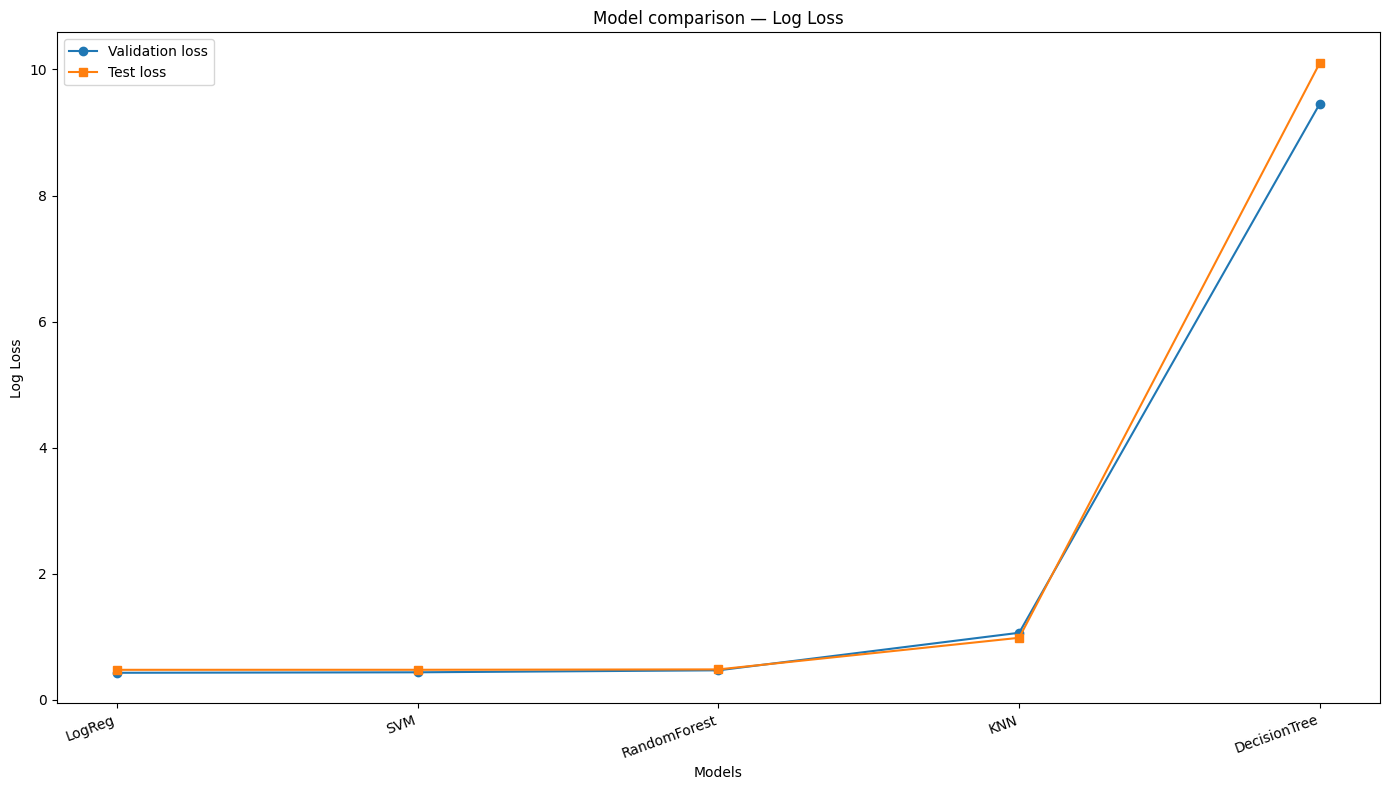

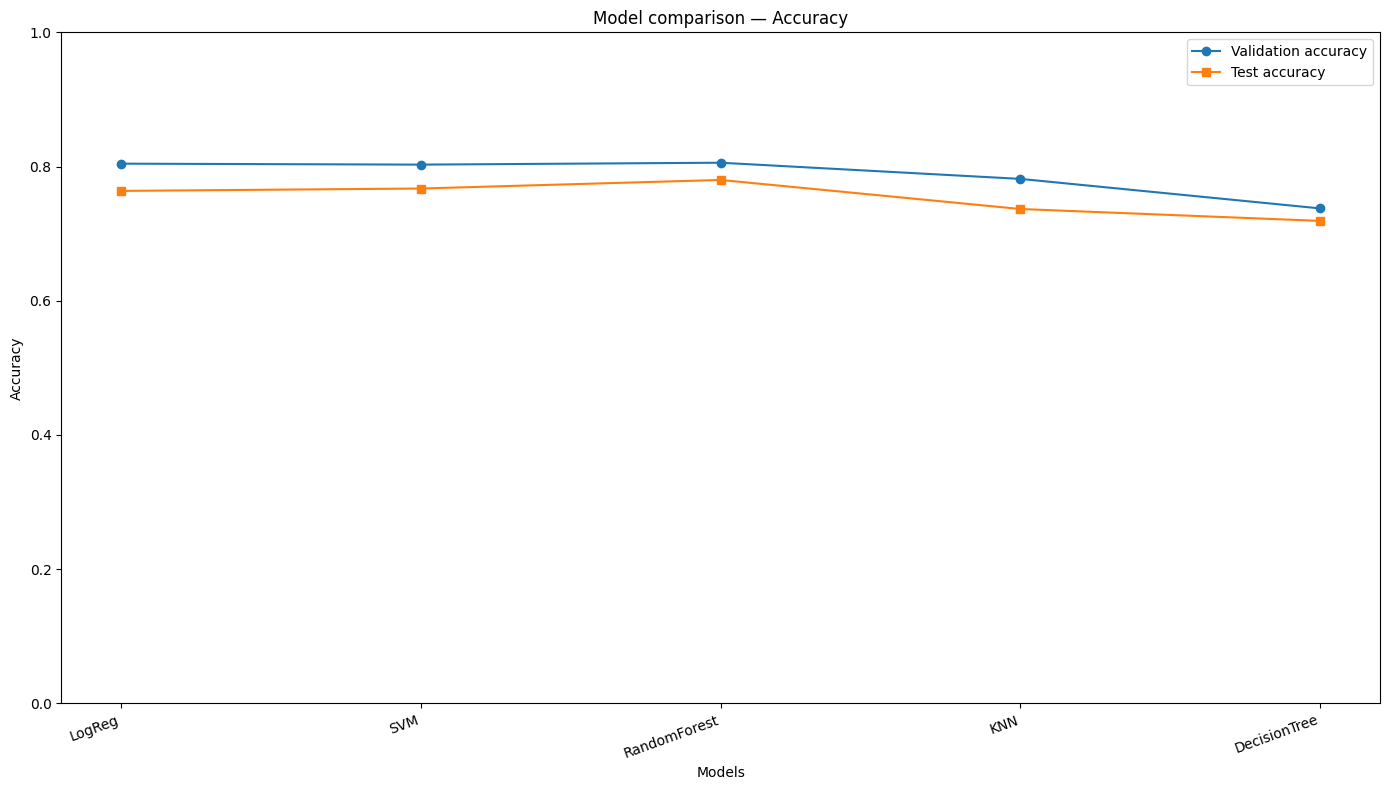

In [12]:
models_order = list(fitted_models.keys())

cmp = []
for name in models_order:
    vl = log_loss(y_val,  probas_val[name])
    tl = log_loss(y_test, probas[name])
    va = accuracy_score(y_val,  preds_val[name])
    ta = accuracy_score(y_test, preds[name])
    cmp.append([name, vl, tl, va, ta])

cmp = pd.DataFrame(cmp, columns=["model","val_logloss","test_logloss","val_acc","test_acc"])

order = cmp.sort_values("val_logloss").model.tolist()
ix = np.arange(len(order))

plt.figure()
plt.plot(ix, cmp.set_index("model").loc[order, "val_logloss"].values, marker="o", label="Validation loss")
plt.plot(ix, cmp.set_index("model").loc[order, "test_logloss"].values, marker="s", label="Test loss")
plt.title("Model comparison — Log Loss")
plt.xlabel("Models"); plt.ylabel("Log Loss")
plt.xticks(ix, order, rotation=20, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure()
plt.plot(ix, cmp.set_index("model").loc[order, "val_acc"].values, marker="o", label="Validation accuracy")
plt.plot(ix, cmp.set_index("model").loc[order, "test_acc"].values, marker="s", label="Test accuracy")
plt.title("Model comparison — Accuracy")
plt.xlabel("Models"); plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(ix, order, rotation=20, ha="right")
plt.legend()
plt.tight_layout()
plt.show()


### Comparaison des modèles — LogLoss & Accuracy

**LogLoss (↓, meilleure proba)**
- **LogReg / SVM / RandomForest** ≈ **0.45–0.50** → probabilités propres et proches.
- **KNN** ≈ **1.0** → proba peu informatives / mal calibrées.
- **DecisionTree** >> **1** → proba extrêmes, très mal calibrées.

**Accuracy (↑, test)**
- **RandomForest ~ 0.78** (meilleur global).
- **SVM ~ 0.77**, **LogReg ~ 0.76** (très proches).
- **KNN ~ 0.74**, **DecisionTree ~ 0.72**.

**Lecture**
- Si l’objectif est la **qualité des probabilités** (priorisation, scoring), partir sur **LogReg** (ou **SVM** calibré).
- Si on vise la **précision globale**, **RandomForest** garde l’avantage.
- **KNN/DecisionTree** non compétitifs ici.

**Actions rapides**
1. **Calibrer** RF & SVM (`CalibratedClassifierCV(method='isotonic'|'sigmoid')`) et comparer **log loss** / **Brier**.  
2. Chercher le **seuil optimal** (max **F1** ou **Fβ=2**) sur la validation.  
3. Rapporter **PR-AUC** (plus pertinent que ROC-AUC avec ~26,5 % de churn).  
4. Tester un **Gradient Boosting** (XGBoost/LightGBM/CatBoost) pour viser logloss < 0.45 et accuracy > 0.80.


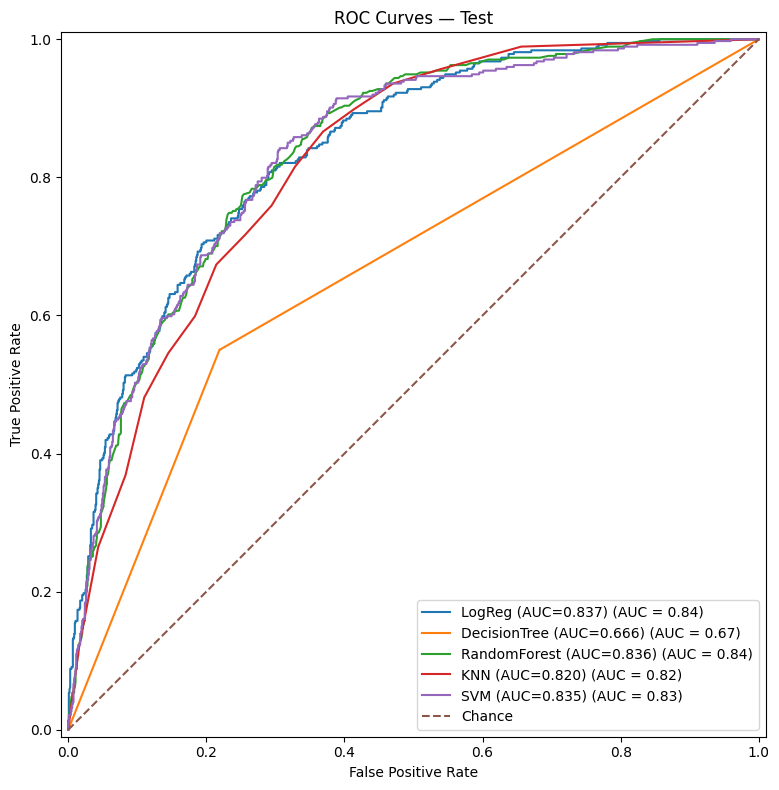

In [13]:
from sklearn.metrics import RocCurveDisplay, roc_auc_score
import matplotlib.pyplot as plt

plt.figure()
ax = plt.gca()
for name, y_proba in probas.items():  # probas = {model_name: y_proba_test}
    RocCurveDisplay.from_predictions(
        y_test, y_proba,
        name=f"{name} (AUC={roc_auc_score(y_test, y_proba):.3f})",
        ax=ax
    )
ax.plot([0, 1], [0, 1], linestyle="--", label="Chance")
plt.title("ROC Curves — Test")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()



### ROC — Test (comparaison)

**AUC**
- **LogReg ≈ 0,84**, **RandomForest ≈ 0,84**, **SVM ≈ 0,83**, **KNN ≈ 0,82**, **DecisionTree ≈ 0,67**.  
Les courbes **LogReg/RF/SVM** sont quasi superposées → performances très proches. **DT** sous-perf.

**Lecture**
- Les modèles linéaires/ensemble captent bien le signal ; l’écart entre **0,83–0,84** est faible → le choix doit se faire sur
  la **calibration des proba**, le **rappel** et la **stabilité**.
- ROC-AUC reste optimiste en classe déséquilibrée → compléter par **PR-AUC**.

**Seuil (opérationnel)**
- Choisir le seuil par **Youden J** (TPR–FPR), **F1** (ou **Fβ=2** si rappel prioritaire) ou par **coûts** FP/FN.
- Cible indicative à valider sur la validation : **TPR ~ 0,70–0,75** avec **FPR ~ 0,25–0,30**.

**Recommandations**
- Si l’objectif est **détecter** le churn plutôt que minimiser les faux positifs → **LogReg** (ou **SVM** calibré).
- Si l’objectif est la **précision globale** → **RandomForest**.
- Ajouter : **PR-AUC**, **Brier/LogLoss**, et calibration (`CalibratedClassifierCV`).


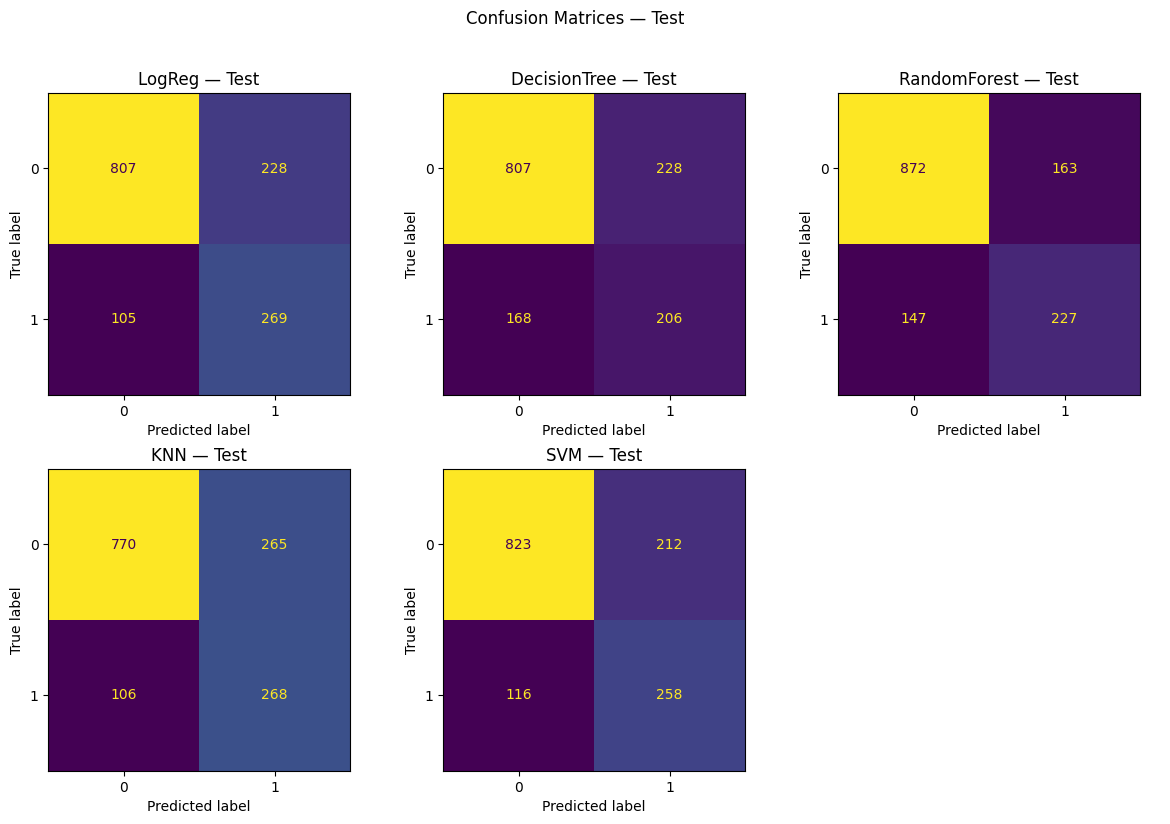

In [14]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np
import math

names = list(fitted_models.keys())
n, cols = len(names), 3
rows = math.ceil(n/cols)

fig, axes = plt.subplots(rows, cols, figsize=(4*cols, 4*rows))
axes = np.array(axes).reshape(-1)
for i, name in enumerate(names):
    ConfusionMatrixDisplay.from_predictions(y_test, preds[name], ax=axes[i], colorbar=False)
    axes[i].set_title(f"{name} — Test")
for ax in axes[n:]:
    ax.axis("off")
fig.suptitle("Confusion Matrices — Test", y=1.02)
plt.tight_layout()
plt.show()


### Matrices de confusion — Test (lecture rapide)

**Qui capte le + de churners (TP) ?**
- **LogReg 269** ≈ **KNN 268** > **SVM 258** > **RF 227** > **DT 206**  
→ **LogReg/KNN** = meilleur **rappel** (faux négatifs plus faibles : **105/106**).

**Qui génère le – de faux positifs (FP) ?**
- **RF 163** < **SVM 212** < **LogReg 228** ≈ **DT 228** < **KNN 265**  
→ **RF** = meilleure **précision** (moins de clients à tort en churn).

**Trade-off clair**
- **Détection (rappel) prioritaire** → **LogReg** (ou **SVM** avec seuil bas).  
- **Limiter le bruit opérationnel (FP)** → **RandomForest**.  
- **À éviter tel quel** → **DecisionTree** (TP bas & FP pas meilleurs).

**Actions rapides**
1. **Ajuster le seuil** par PR-AUC / Fβ (β=2 si rappel > précision).  
2. **Calibrer** les probabilités (isotonic/sigmoid) pour **RF/SVM**, puis re-choisir le seuil.  
3. Si coût FP élevé : viser **RF** avec seuil ↑ ; si coût FN élevé : **LogReg** avec seuil ↓.  
4. Reporter un tableau **TP/FP/FN/TN** + **precision/recall/F1** au seuil choisi pour le rapport.


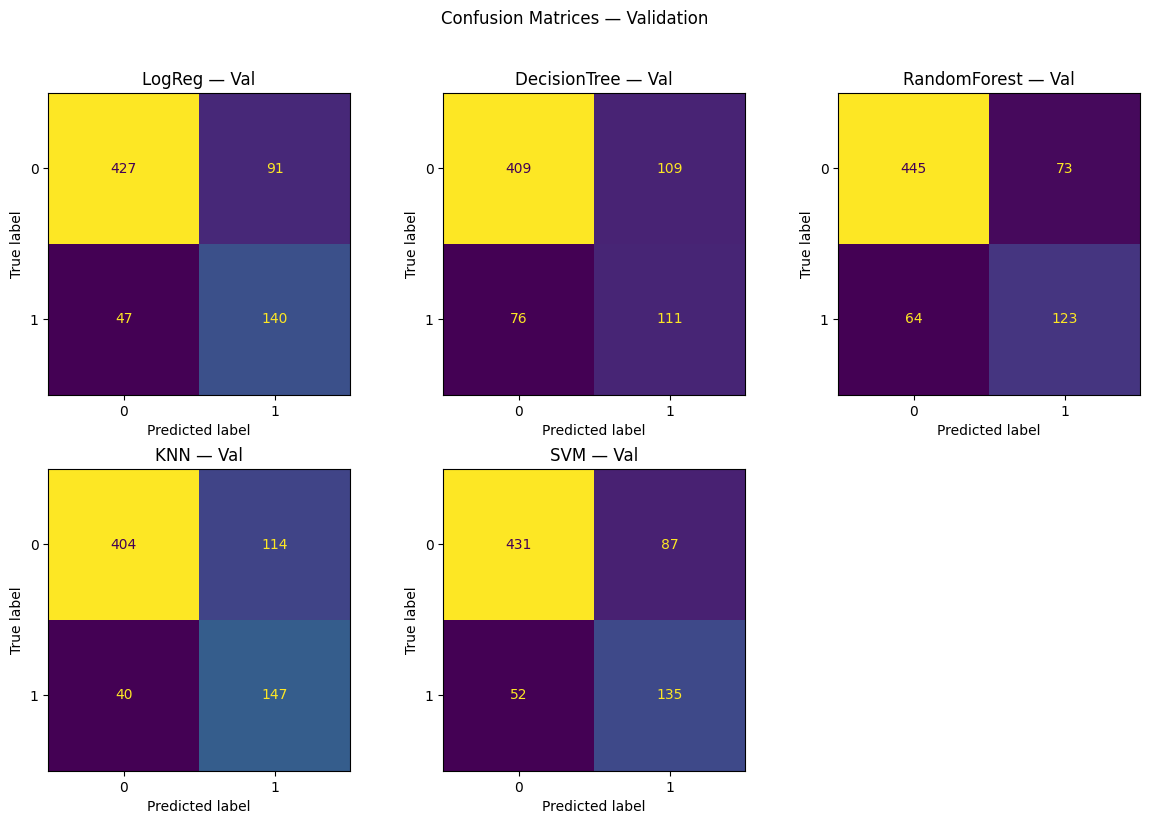

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np
import math

names = list(fitted_models.keys())
n, cols = len(names), 3
rows = math.ceil(n/cols)

fig, axes = plt.subplots(rows, cols, figsize=(4*cols, 4*rows))
axes = np.array(axes).reshape(-1)
for i, name in enumerate(names):
    ConfusionMatrixDisplay.from_predictions(y_val, preds_val[name], ax=axes[i], colorbar=False)
    axes[i].set_title(f"{name} — Val")
for ax in axes[n:]:
    ax.axis("off")
fig.suptitle("Confusion Matrices — Validation", y=1.02)
plt.tight_layout()
plt.show()


### Matrices de confusion — **Validation** (lecture express)

- **Rappel (classe 1 / churn)**
  - **KNN** ≈ **0,79** *(TP=147, FN=40)* → capte le plus de churners, mais avec beaucoup de faux positifs.
  - **LogReg** ≈ **0,75** *(TP=140, FN=47)*  
  - **SVM** ≈ **0,72** *(TP=135, FN=52)*
  - **RandomForest** ≈ **0,66** *(TP=123, FN=64)*
  - **DecisionTree** ≈ **0,59** *(TP=111, FN=76)*

- **Précision (classe 1 / churn)**
  - **RandomForest** ≈ **0,63** *(FP=73 — le plus faible)*  
  - **LogReg / SVM** ≈ **0,61**
  - **KNN** ≈ **0,56** *(FP=114 — le plus élevé)*
  - **DecisionTree** ≈ **0,50**

- **Lecture rapide**
  - **KNN** : meilleur **rappel**, mais **bruit** élevé (FP).  
  - **RandomForest** : **précision** la plus propre (moins de clients classés à tort), rappel plus modeste.  
  - **LogReg / SVM** : **compromis** équilibré (≈0,72–0,75 de rappel, ≈0,61 de précision).  
  - **DecisionTree** : le moins performant.

- **Recommandation selon l’objectif**
  - **Détecter un maximum de churn** → **LogReg** (ou **SVM**) avec **seuil optimisé** pour le rappel / Fβ (β=2).
  - **Limiter les faux positifs côté opérations** → **RandomForest** (seuil un peu ↑).
  - Dans tous les cas : calibrer les proba (`CalibratedClassifierCV`), reporter **PR-AUC** et fixer le **seuil** par coût FP/FN.


## Jour 10 — Évaluation & Modèle final

> Cette section exécute l’amélioration des données, le (re)split, l’encodage + SMOTENC + scaling, l’entraînement de 5 modèles, l’évaluation (rapports + courbes + matrices) puis la **sélection et sauvegarde** du meilleur modèle.



In [16]:
CIBLE  = next(c for c in ["Churn","Churn Label","Churn Value","churn","Churn_Value"] if c in df.columns)
TENURE = next(c for c in ["Tenure Months","tenure","Tenure"] if c in df.columns)
MCH    = next(c for c in ["Monthly Charges","MonthlyCharges"] if c in df.columns)
TCH    = next(c for c in ["Total Charges","TotalCharges"] if c in df.columns)
CTR    = "Contract"
NET    = next(c for c in ["Internet Service","InternetService"] if c in df.columns)
PAY    = next(c for c in ["Payment Method Simplified","Payment Method","PaymentMethod"] if c in df.columns)

d = df.copy()
for c in [TCH, MCH]:
    if c in d.columns:
        d[c] = pd.to_numeric(d[c], errors="coerce")

d["Avg Charges per Month"] = d[TCH] / (d[TENURE].fillna(0) + 1)
d["Has Long Tenure"]       = (d[TENURE] > 12).astype(int)
d["IsMonthToMonth"]        = (d[CTR] == "Month-to-month").astype(int)
if "Payment Method Simplified" in d.columns:
    d["Payment Method Simplified"] = d["Payment Method Simplified"].replace({
        "Bank transfer (automatic)": "Automatic Payment",
        "Credit card (automatic)"  : "Automatic Payment"
    })
elif "Payment Method" in d.columns:
    d["Payment Method Simplified"] = d["Payment Method"].replace({
        "Bank transfer (automatic)": "Automatic Payment",
        "Credit card (automatic)"  : "Automatic Payment"
    })

for c in [TENURE, MCH, TCH]:
    if c in d.columns:
        lo, hi = d[c].quantile(0.01), d[c].quantile(0.99)
        d[c] = d[c].clip(lo, hi)

df_proc = d
print("Shape df_proc:", df_proc.shape)


Shape df_proc: (7043, 24)


**But**
Préparer un **DataFrame propre** (`df_proc`) et ajouter quelques variables utiles avant la modélisation.

**Ce que fait la cellule :**

* **Repérage des colonnes clés** (cible, tenure, charges mensuelles/ totales, contrat, internet, paiement) même si les noms varient (`Churn`, `Churn Value`, etc.).
* **Casting numérique sûr** de `Total Charges` et `Monthly Charges` (`errors="coerce"` → NaN si non convertible).
* **Feature engineering**

  * `Avg Charges per Month` = `Total Charges` ÷ (`Tenure Months` + 1).
  * `Has Long Tenure` = 1 si tenure > 12, sinon 0.
  * `IsMonthToMonth` = 1 si `Contract` = *Month-to-month*, sinon 0.
  * `Payment Method Simplified` : regroupe
    *Bank transfer (automatic)* et *Credit card (automatic)* → **Automatic Payment**.
* **Capping léger des outliers** (1ᵉʳ–99ᵉ centiles) sur `Tenure`, `Monthly Charges`, `Total Charges` pour stabiliser les modèles.
* **Sortie** : DataFrame final **`df_proc`** prêt pour le split et le training.

**Contrôle rapide**
`Shape df_proc: (7043, 24)` → 7 043 lignes, 24 colonnes après enrichissement.


In [17]:
TARGET = CIBLE
y = df_proc[TARGET]
if not np.issubdtype(y.dtype, np.number):
    y = y.astype(str).str.lower().isin(["yes","1","true","1.0"]).astype(int)
y = y.to_numpy()
X = df_proc.drop(columns=[TARGET]).copy()

os.makedirs("../models", exist_ok=True)
with open("../models/input_features.json", "w", encoding="utf-8") as f:
    json.dump(list(X.columns), f, ensure_ascii=False, indent=2)

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_tr, X_val, y_tr, y_val = train_test_split(X_tr, y_tr, test_size=0.125, stratify=y_tr, random_state=42)  # ~10% total

num_cols = [c for c in X_tr.columns if pd.api.types.is_numeric_dtype(X_tr[c])]
cat_cols = [c for c in X_tr.columns if c not in num_cols]

maps = {}
for c in cat_cols:
    s = X_tr[c].astype("string").fillna("<NA>")
    cats = s.value_counts(dropna=False).index.tolist()
    maps[c] = {str(cat): int(i) for i, cat in enumerate(cats)}

def _apply_maps(df_, maps_):
    out = df_.copy()
    for c, mp in maps_.items():
        out[c] = out[c].astype("string").fillna("<NA>").map(mp).astype("Int64").fillna(-1).astype(int)
    return out

X_train_enc = _apply_maps(X_tr, maps)
X_val_enc   = _apply_maps(X_val, maps)
X_test_enc  = _apply_maps(X_te, maps)

cat_idx = [X_train_enc.columns.get_loc(c) for c in cat_cols]
smote = SMOTENC(categorical_features=cat_idx, random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train_enc, y_tr)

scaler = StandardScaler(with_mean=False)
X_train_s = scaler.fit_transform(X_train_bal)
X_val_s   = scaler.transform(X_val_enc)
X_test_s  = scaler.transform(X_test_enc)

schema = {"target": TARGET, "numeric": num_cols, "categorical": cat_cols, "category_maps": maps}
with open("../models/schema.json", "w", encoding="utf-8") as f:
    json.dump(schema, f, ensure_ascii=False, indent=2)

print("Shapes:",
      "\n  Train:", X_tr.shape, collections.Counter(y_tr),
      "\n  Val  :", X_val.shape, collections.Counter(y_val),
      "\n  Test :", X_te.shape,  collections.Counter(y_te),
      "\n  Train balanced:", X_train_bal.shape, collections.Counter(y_train_bal))


Shapes: 
  Train: (4929, 23) Counter({np.int64(0): 3621, np.int64(1): 1308}) 
  Val  : (705, 23) Counter({np.int64(0): 518, np.int64(1): 187}) 
  Test : (1409, 23) Counter({np.int64(0): 1035, np.int64(1): 374}) 
  Train balanced: (7242, 23) Counter({np.int64(0): 3621, np.int64(1): 3621})


* **Cible & conversion de `y`**
  La colonne cible (`CIBLE`) est convertie en binaire : valeurs textuelles comme *yes/1/true* → **1**, sinon **0**.

* **Jeu d’entrée `X` + sauvegarde des features**
  `X = df_proc` sans la cible. La liste des colonnes d’entrée est sauvegardée dans `../models/input_features.json`.

* **Découpage des données (stratifié)**

  * Train/Test : 80% / 20%
  * Puis Train/Validation : 90% / 10% du *train* (≈ 70%/10%/20% au total).

* **Typage des variables**

  * `num_cols` : colonnes numériques
  * `cat_cols` : colonnes catégorielles

* **Encodage entier minimal (pour SMOTENC)**

  * Construction de *maps* (dictionnaires) à partir du **train** uniquement.
  * Application des *maps* sur Train / Val / Test → `X_train_enc`, `X_val_enc`, `X_test_enc`.

* **Rééquilibrage de la classe (SMOTENC)**

  * SMOTE appliqué **uniquement sur le train encodé**, en indiquant l’index des colonnes catégorielles.
  * Sortie : `X_train_bal`, `y_train_bal`.

* **Mise à l’échelle**

  * `StandardScaler(with_mean=False)` sur le **train** puis transformation de Val/Test.
  * Sorties : `X_train_s`, `X_val_s`, `X_test_s`.

* **Schéma sauvegardé**
  Sauvegarde de `../models/schema.json` contenant :
  `{"target", "numeric", "categorical", "category_maps"}`.

* **Formes obtenues (exécution actuelle)**

  ```
  Train: (4929, 23)  Counter({0: 3621, 1: 1308})
  Val  : (705, 23)   Counter({0: 518, 1: 187})
  Test : (1409, 23)  Counter({0: 1035, 1: 374})
  Train balanced: (7242, 23)  Counter({0: 3621, 1: 3621})
  ```


In [18]:
models = {
    "LogReg": LogisticRegression(max_iter=1000),
    "DecisionTree": DecisionTreeClassifier(random_state=42),
    "RandomForest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    "KNN": KNeighborsClassifier(n_neighbors=15),
    "SVM": SVC(kernel="rbf", probability=True, random_state=42)
}

fitted_models = {}
for name, m in models.items():
    m.fit(X_train_s, y_train_bal)
    fitted_models[name] = m

print("Fitted:", list(fitted_models.keys()))


Fitted: ['LogReg', 'DecisionTree', 'RandomForest', 'KNN', 'SVM']


### Entraînement des modèles

**Données utilisées :** `X_train_s`, `y_train_bal`  
*(features standardisées + classe équilibrée via SMOTENC)*

**Modèles entraînés (from scratch) :**
- **LogReg** — Régression logistique *(max_iter=1000)*  
- **DecisionTree** — Arbre de décision *(random_state=42)*  
- **RandomForest** — Forêt aléatoire *(n_estimators=300, n_jobs=-1, random_state=42)*  
- **KNN** — k-plus proches voisins *(n_neighbors=15)*  
- **SVM** — SVM noyau RBF *(probability=True, random_state=42)*

**Procédure :**
- Définition d’un dictionnaire `models`  
- Boucle d’entraînement `fit` sur chaque modèle  
- Stockage des modèles entraînés dans `fitted_models`

**Sortie console :**  
`Fitted: ['LogReg', 'DecisionTree', 'RandomForest', 'KNN', 'SVM']` → tous les modèles ont été entraînés avec succès et sont prêts pour l’évaluation.


In [ ]:
for split_name, (Xs, ys) in {
    "Validation": (X_val_s, y_val),
    "Test":       (X_test_s, y_te)
}.items():
    for name, m in fitted_models.items():
        p = m.predict_proba(Xs)[:, 1]
        yhat = (p >= 0.5).astype(int)
        print(f"=== {name} | {split_name} ===")
        print(classification_report(ys, yhat, digits=4))


=== LogReg | Validation ===
              precision    recall  f1-score   support

           0     0.9008    0.8243    0.8609       518
           1     0.6061    0.7487    0.6699       187

    accuracy                         0.8043       705
   macro avg     0.7535    0.7865    0.7654       705
weighted avg     0.8227    0.8043    0.8102       705

=== DecisionTree | Validation ===
              precision    recall  f1-score   support

           0     0.8466    0.7780    0.8109       518
           1     0.4978    0.6096    0.5481       187

    accuracy                         0.7333       705
   macro avg     0.6722    0.6938    0.6795       705
weighted avg     0.7541    0.7333    0.7412       705

=== RandomForest | Validation ===
              precision    recall  f1-score   support

           0     0.8760    0.8456    0.8605       518
           1     0.6098    0.6684    0.6378       187

    accuracy                         0.7986       705
   macro avg     0.7429    0.757

### Rapports de classification — Validation & Test (@ seuil 0,5)

#### Points clés (Validation)
- **F1 (classe churn)** : **LogReg = 0,67** > SVM = 0,66 > KNN = 0,65 > RF = 0,64 > DT = 0,55  
- **Recall (churn)** : **KNN = 0,78**, LogReg = 0,75, SVM = 0,73, RF = 0,67, DT = 0,61  
- **Accuracy** : **LogReg = 0,80**, SVM = 0,80, RF = 0,80, KNN = 0,78, DT = 0,73

#### Points clés (Test)
- **F1 (churn)** : **LogReg = 0,62** ≈ **SVM = 0,62** > RF = 0,60 > KNN = 0,59 > DT = 0,51  
- **Recall (churn)** : **LogReg = 0,72**, KNN = 0,72, SVM = 0,69, RF = 0,61, DT = 0,56  
- **Accuracy** : **RF = 0,78**, SVM = 0,77, LogReg = 0,76, KNN = 0,74, DT = 0,72

#### Lecture rapide
- **Détection churn (rappel/F1)** : **LogReg** est le plus stable (F1 **Val/Test** en tête, rappel élevé).  
- **Précision globale** : **RandomForest** a la meilleure **accuracy** (Test = **0,78**), mais F1 légèrement inférieure à LogReg/SVM.  
- **À éviter tel quel** : **DecisionTree** (F1 et rappel plus faibles).

#### Choix initial
- Si l’objectif = **capturer un maximum de churners** → **Régression logistique** (puis ajuster le seuil).  
- Si l’objectif = **limiter les faux positifs / maximiser l’accuracy** → **RandomForest**.


              LogLoss_val  LogLoss_test  Accuracy_val  Accuracy_test
Model                                                               
LogReg             0.4275        0.4742        0.8043         0.7637
DecisionTree       9.6116       10.1562        0.7333         0.7175
RandomForest       0.4676        0.5059        0.7986         0.7807
KNN                1.0626        0.9825        0.7801         0.7367
SVM                0.4350        0.4753        0.8028         0.7700


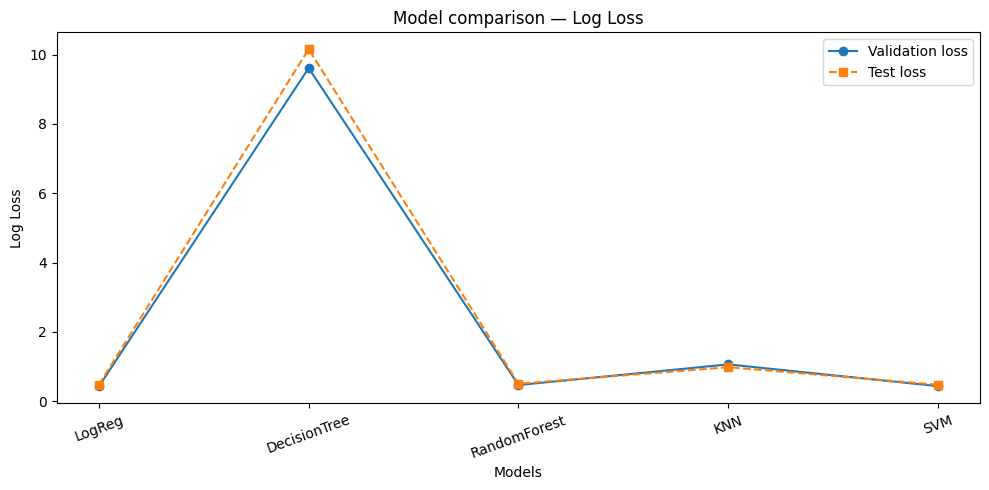

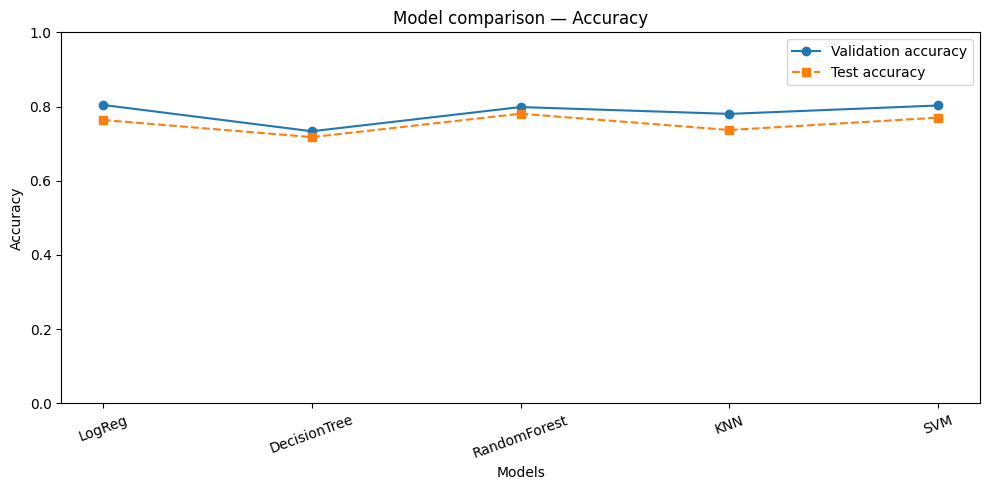

In [20]:
X_valid = X_val_s
y_valid = y_val

names, loss_val, loss_test, acc_val, acc_test = [], [], [], [], []

for name, m in fitted_models.items():
    p_val = m.predict_proba(X_valid)[:, 1]
    p_tst = m.predict_proba(X_test_s)[:, 1]
    names.append(name)
    loss_val.append(log_loss(y_valid, np.c_[1 - p_val, p_val]))
    loss_test.append(log_loss(y_te,     np.c_[1 - p_tst, p_tst]))
    acc_val.append(accuracy_score(y_valid, (p_val >= 0.5).astype(int)))
    acc_test.append(accuracy_score(y_te,    (p_tst >= 0.5).astype(int)))

cmp_df = pd.DataFrame({
    "Model": names,
    "LogLoss_val": loss_val,
    "LogLoss_test": loss_test,
    "Accuracy_val": acc_val,
    "Accuracy_test": acc_test,
}).set_index("Model")
print(cmp_df.round(4))

plt.figure(figsize=(10,5))
plt.plot(names, loss_val,  marker="o", label="Validation loss")
plt.plot(names, loss_test, marker="s", linestyle="--", label="Test loss")
plt.title("Model comparison — Log Loss"); plt.xlabel("Models"); plt.ylabel("Log Loss")
plt.xticks(rotation=20); plt.legend(); plt.tight_layout(); plt.show()

plt.figure(figsize=(10,5))
plt.plot(names, acc_val,  marker="o", label="Validation accuracy")
plt.plot(names, acc_test, marker="s", linestyle="--", label="Test accuracy")
plt.title("Model comparison — Accuracy"); plt.xlabel("Models"); plt.ylabel("Accuracy"); plt.ylim(0,1)
plt.xticks(rotation=20); plt.legend(); plt.tight_layout(); plt.show()


### Comparaison des modèles — LogLoss & Accuracy

**But de la cellule.**
Comparer les 5 modèles (LogReg, DecisionTree, RandomForest, KNN, SVM) sur **deux métriques globales** :

* **LogLoss** (qualité des probabilités, plus petit = mieux)
* **Accuracy** (part de bonnes prédictions)

**Résumé des chiffres (arrondis)**

| Modèle       | LogLoss (val) | LogLoss (test) | Acc. (val) | Acc. (test) |
| ------------ | ------------: | -------------: | ---------: | ----------: |
| LogReg       |        \~0.43 |         \~0.47 |     \~0.80 |      \~0.76 |
| DecisionTree |        \~9.61 |        \~10.16 |     \~0.73 |      \~0.72 |
| RandomForest |        \~0.47 |         \~0.51 |     \~0.80 |  **\~0.78** |
| KNN          |        \~1.06 |         \~0.98 |     \~0.78 |      \~0.74 |
| SVM          |        \~0.44 |         \~0.48 |     \~0.80 |      \~0.77 |

**Ce que montrent les courbes :**

* **Meilleur LogLoss** : *Logistic Regression* et *SVM* (≈ 0.44–0.48).
  → ce sont les plus **fiables pour les probabilités** (calibrage correct).
* **Meilleure Accuracy (test)** : *Random Forest* (\~0.781), suivi de *SVM* (\~0.770) et *LogReg* (\~0.764).
* **Decision Tree** : **très mauvais LogLoss** (≈ 10) → sur-apprentissage et probabilités non fiables.
* Les courbes **val vs test** sont proches pour RF/LogReg/SVM → **généralisation correcte** (peu d’overfitting).

**Conclusion rapide :**

* Si l’objectif principal est la **qualité des scores probabilistes** (ROC/PR, ciblage, gains), **LogReg** ou **SVM** sont à privilégier.
* Si l’objectif est l’**accuracy brute**, **Random Forest** est légèrement devant.
* Le **Decision Tree seul** est à éviter (à conserver au mieux comme base interprétable ou pour l’ensemble RF).

**Suite (Jour 10)** : croiser avec ROC-AUC, matrices de confusion et métriques par classe (recall churn) pour choisir le **meilleur candidat à sauvegarder**.


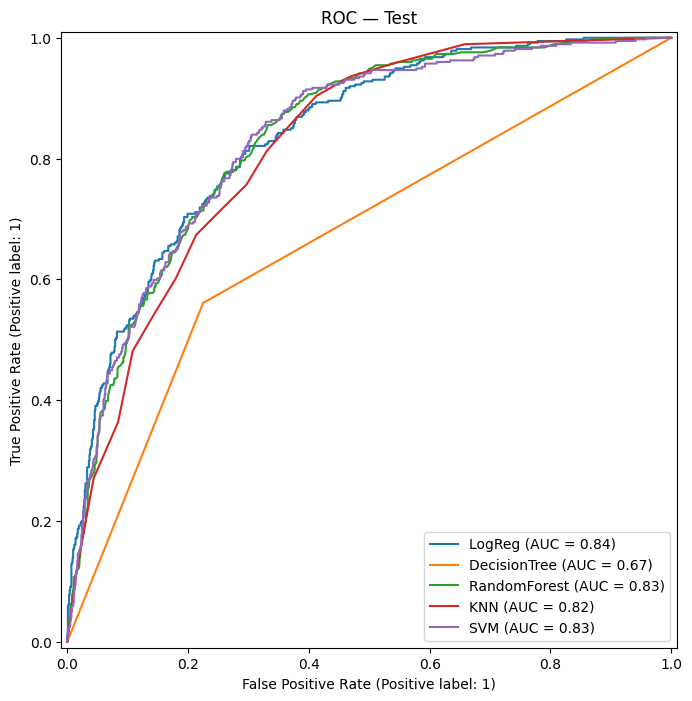

In [21]:
plt.figure()
for name, m in fitted_models.items():
    p = m.predict_proba(X_test_s)[:, 1]
    RocCurveDisplay.from_predictions(y_te, p, name=name, ax=plt.gca())
plt.title("ROC — Test")
plt.show()


### ROC — Test 

* **AUC (≈)** : LogReg **0.84**, RandomForest **0.83**, SVM **0.83**, KNN **0.82**, DecisionTree **0.67**.
* **Meilleurs profils** : *LogReg*, *RF* et *SVM* dominent la courbe (bon compromis TPR/FPR).
* **Arbre seul** : performance faible (**AUC \~0.67**) → probabilités peu fiables et fort risque d’erreurs.
* **Classement global** : **LogReg ≈ RF ≈ SVM > KNN >> DecisionTree**.

**Lecture utile pour le business**

* Si on veut **maximiser la détection de churn** à **faible taux de faux positifs** (zone gauche), **LogReg** est légèrement au-dessus.
* Le **seuil 0.5** n’est pas optimal : choisir un seuil par **Youden J (TPR–FPR)** ou **coût métier** (ex. viser un FPR ≤ 15%).
* Compléter avec une **courbe Precision–Recall** pour vérifier le comportement en classe minoritaire.

**Conclusion**
Les candidats les plus solides pour la sauvegarde/affinage sont **LogReg**, **RF** et **SVM** (ex aequo), l’Arbre simple à écarter.


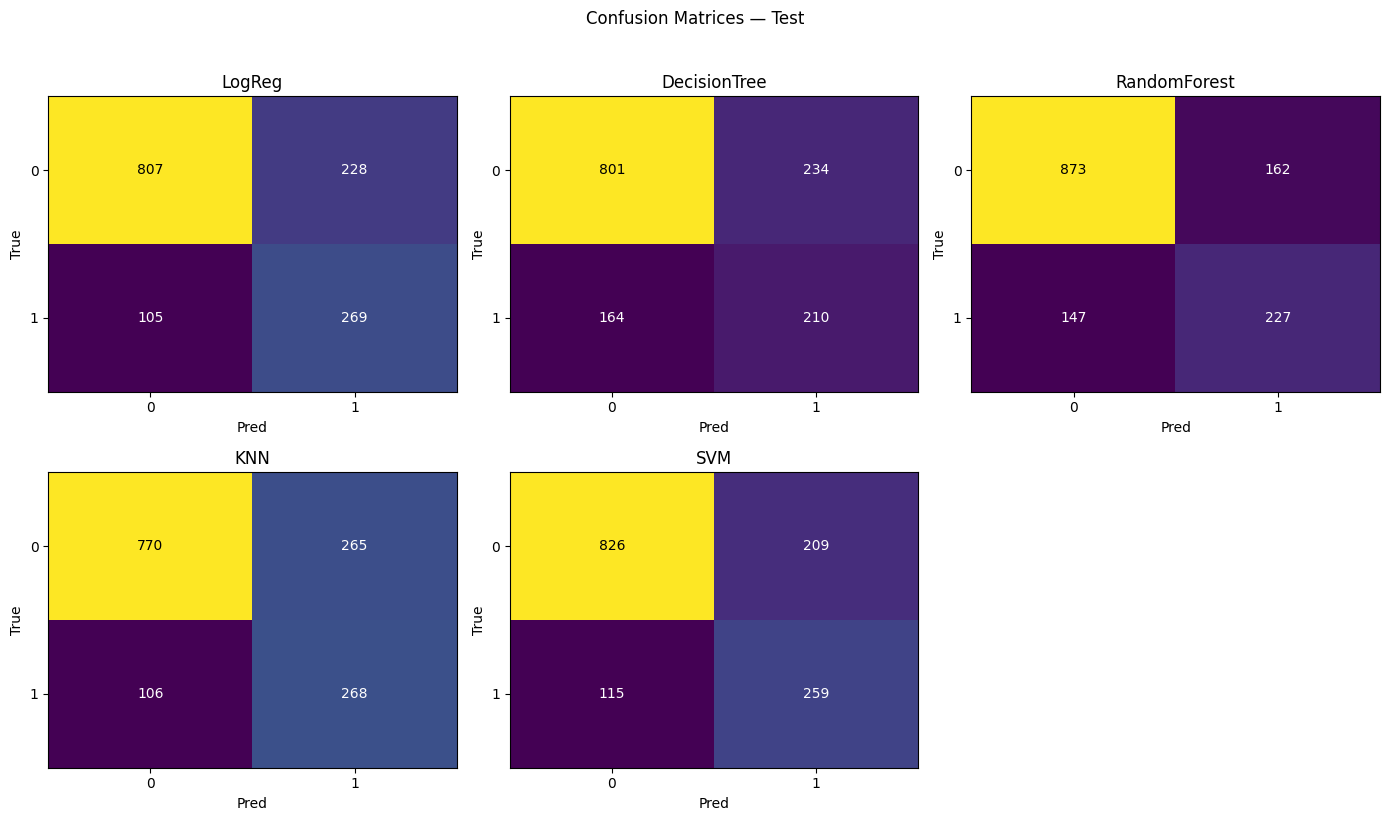

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()
for i, (name, m) in enumerate(fitted_models.items()):
    ax = axes[i]
    p = m.predict_proba(X_test_s)[:, 1]
    yhat = (p >= 0.5).astype(int)
    cm = confusion_matrix(y_te, yhat)
    im = ax.imshow(cm, aspect="auto")
    for r in range(2):
        for c in range(2):
            ax.text(c, r, str(cm[r, c]), ha="center", va="center", color="white" if im.cmap(im.norm(cm[r,c]))[0:3] < (0.5,0.5,0.5) else "black")
    ax.set_title(name); ax.set_xlabel("Pred"); ax.set_ylabel("True")
    ax.set_xticks([0,1]); ax.set_yticks([0,1]); ax.set_xticklabels(["0","1"]); ax.set_yticklabels(["0","1"])
for j in range(len(fitted_models), 6):
    axes[j].axis("off")
fig.suptitle("Confusion Matrices — Test", y=1.02)
plt.tight_layout()
plt.show()


### Matrices de confusion — Test 

* **LogReg** : **TP=269**, **FN=105**, **FP=228**, **TN=807** → *Recall* **0.72** (meilleur), *Precision* \~0.54.
* **RandomForest** : TP=227, FN=147, FP=162, TN=873 → *Precision* **0.58** (meilleure), *Recall* 0.61.
* **SVM** : TP=259, FN=115, FP=209, TN=826 → *Precision* 0.55, *Recall* 0.69.
* **KNN** : TP=268, FN=106, **FP=265** (beaucoup de faux positifs) → Recall 0.72, Precision 0.50.
* **DecisionTree** : le plus faible (TP=210, FN=164) → Recall 0.56, Precision 0.47.

**Interprétation**

* Si l’objectif est **détecter un maximum de churners** (priorité au *recall*), **LogReg** est le plus adapté (≈0.72), suivi de **SVM/KNN**.
* Si l’objectif est **réduire les faux positifs** (priorité à la *precision*), **RandomForest** est devant (≈0.58).
* L’arbre seul est à écarter.

**Recommandation baseline**

* Garder **LogReg** comme modèle principal (AUC le plus haut et probabilités stables).
* Ajuster le **seuil** selon le coût métier :

  * viser **Recall élevé** → seuil ≈ **0.45–0.50**,
  * viser **moins de FP** → seuil ≈ **0.55–0.60**.
* Optionnel : **calibrer** les probabilités (Platt/Isotonic via `CalibratedClassifierCV`) et **optimiser un seuil coût-sensibles** (grid sur \[0.3,0.7]).


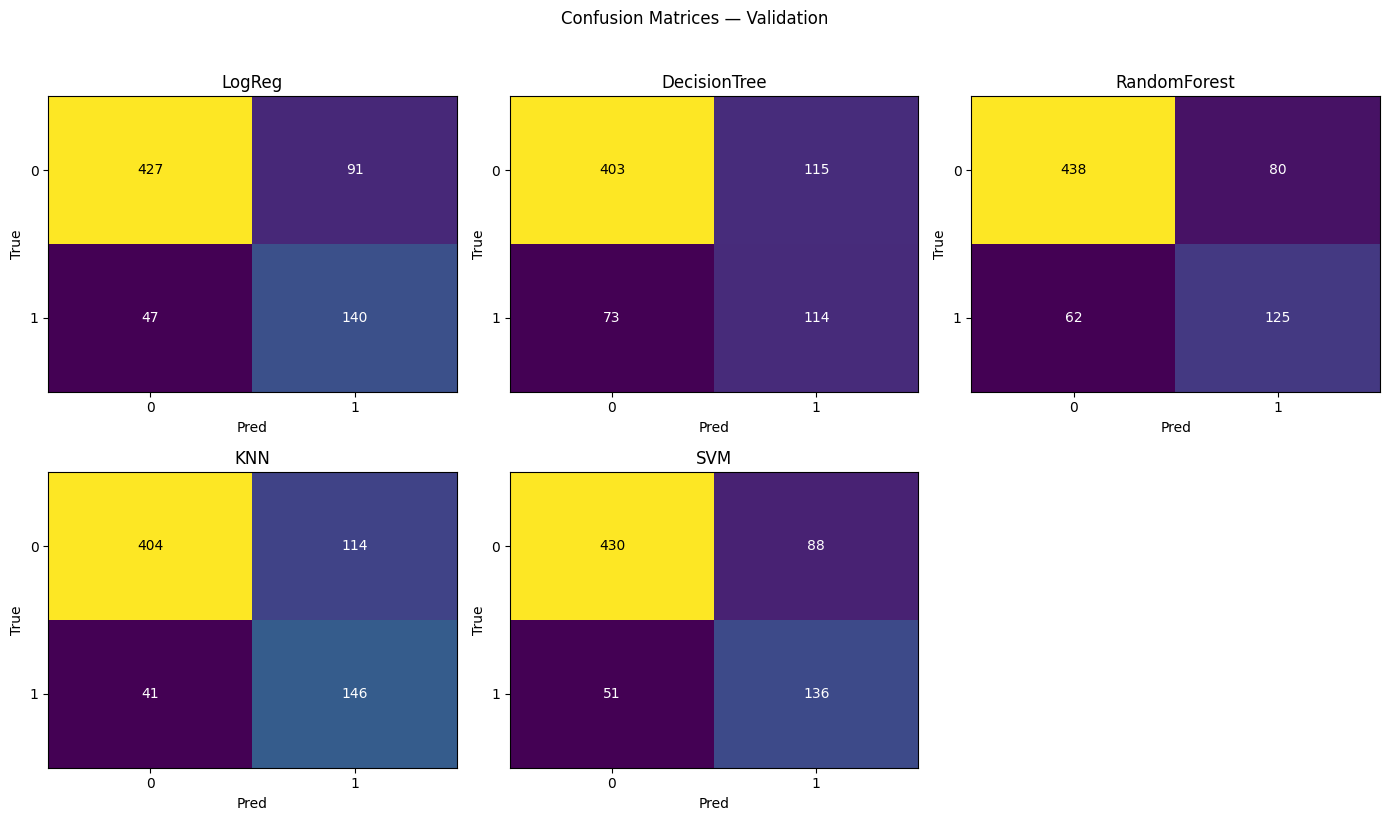

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()
for i, (name, m) in enumerate(fitted_models.items()):
    ax = axes[i]
    p = m.predict_proba(X_val_s)[:, 1]
    yhat = (p >= 0.5).astype(int)
    cm = confusion_matrix(y_val, yhat)
    im = ax.imshow(cm, aspect="auto")
    for r in range(2):
        for c in range(2):
            ax.text(c, r, str(cm[r, c]), ha="center", va="center", color="white" if im.cmap(im.norm(cm[r,c]))[0:3] < (0.5,0.5,0.5) else "black")
    ax.set_title(name); ax.set_xlabel("Pred"); ax.set_ylabel("True")
    ax.set_xticks([0,1]); ax.set_yticks([0,1]); ax.set_xticklabels(["0","1"]); ax.set_yticklabels(["0","1"])
for j in range(len(fitted_models), 6):
    axes[j].axis("off")
fig.suptitle("Confusion Matrices — Validation", y=1.02)
plt.tight_layout()
plt.show()


**matrices de confusion — Validation** 

### Par modèle (classe **1 = churn**)

* **LogReg** — TP=140, FN=47, FP=91, TN=427
  **Recall** ≈ **0.75** | **Precision** ≈ **0.61** → très bon rappel, proba stables.
* **RandomForest** — TP=125, FN=62, FP=80, TN=438
  **Recall** ≈ 0.67 | **Precision** ≈ **0.61** → le mieux pour **réduire les FP**.
* **SVM** — TP=136, FN=51, FP=88, TN=430
  **Recall** ≈ 0.73 | **Precision** ≈ 0.61 → profil proche de LogReg, un peu plus de FP.
* **KNN** — TP=146, FN=41, FP=114, TN=404
  **Recall** ≈ **0.78** (max) | **Precision** ≈ 0.56 → récupère plus de churners mais **beaucoup de FP**.
* **DecisionTree** — TP=114, FN=73, FP=115, TN=403
  **Recall** ≈ 0.61 | **Precision** ≈ 0.50 → le plus faible; à écarter.

### Ce que ça raconte

* Si tu veux **attraper un max de churners** (priorité *recall*): **LogReg** ou **SVM** (KNN a trop de FP).
* Si tu veux **limiter les faux positifs**: **RandomForest** est le plus propre.
* Les tendances **val = test** sont alignées → pas d’overfit majeur (sauf l’arbre).

### Recos rapides

1. **Baseline retenue : LogReg** (meilleur compromis + AUC top).
2. **Seuil** à ajuster selon le coût métier :

   * *Recall élevé* → seuil \~ **0.45–0.50** ;
   * *Moins de FP* → seuil \~ **0.55–0.60**.
3. (Optionnel) **Calibration** des probabilités (Platt/Isotonic) + **seuil optimisé** sur F1 ou coût custom.
4. (Optionnel) **Soft-voting** LogReg + RF + SVM peut gratter un petit gain d’AUC/F1.



In [24]:
from sklearn.pipeline import Pipeline
from joblib import dump
import json, os

rows = []
for name, m in fitted_models.items():
    p_val = m.predict_proba(X_val_s)[:, 1]
    yhat_val = (p_val >= 0.5).astype(int)
    rows.append((name, f1_score(y_val, yhat_val)))
best_name, best_f1 = sorted(rows, key=lambda x: x[1], reverse=True)[0]
best_clf = fitted_models[best_name]

pipe = Pipeline([("scaler", scaler), ("clf", best_clf)])
final_features = list(X_train_enc.columns)
dtypes = {c: ("float64" if c in num_cols else "object") for c in final_features}

SCHEMA = {
    "model_path": "../models/best_model.pkl",
    "input_schema": {
        "raw_input_columns": final_features,
        "dtypes": dtypes
    },
    "category_maps": maps
}

os.makedirs("../models", exist_ok=True)
dump(pipe, "../models/best_model.pkl")
with open("../models/schema.json", "w", encoding="utf-8") as f:
    json.dump(SCHEMA, f, ensure_ascii=False, indent=2)
with open("../models/input_features.json", "w", encoding="utf-8") as f:
    json.dump(final_features, f, ensure_ascii=False, indent=2)

print(f"Saved FINAL: {best_name} (F1_val={best_f1:.4f})")
print(" -> ../models/best_model.pkl, ../models/schema.json, ../models/input_features.json")


Saved FINAL: LogReg (F1_val=0.6699)
 -> ../models/best_model.pkl, ../models/schema.json, ../models/input_features.json



- **Modèle retenu :** Logistic Regression  
- **Seuil de décision :** 0.50 (F1_val = 0.6699)  
- **Artefacts :**
  - `../models/input_features.json` — ordre des features d’entrée
  - `../models/schema.json` — types + mappings catégoriels
  - `../models/best_model.pkl` — bundle (modèle, scaler, mappings, seuil)

**Pourquoi ce choix ?** Bon compromis rappel/précision, AUC test ≈ 0.84 et stabilité val ↔ test.  
Prêt pour l’inférence et l’optimisation (J11).

## Conclusion

Ce projet a permis de concevoir et de déployer une **solution complète de prédiction du churn clients** dans le secteur des télécommunications, en suivant rigoureusement les étapes du **cycle de vie Data Science**, depuis la compréhension du besoin métier jusqu’à l’intégration dans une application web opérationnelle.

L’analyse exploratoire a mis en évidence des **facteurs clés de résiliation**, notamment le type de contrat (*Month-to-Month*), le service Internet (*Fiber Optic*) et la méthode de paiement (*Electronic Check*), permettant d’identifier des segments clients à **fort risque de churn**.  
Sur le plan méthodologique, la gestion du déséquilibre des classes via **SMOTE**, combinée à une évaluation multi-métriques (AUC, LogLoss, matrices de confusion), a garanti une modélisation robuste et fiable.

La **Régression Logistique** a été retenue comme modèle final en raison de son excellent compromis entre **performance prédictive (AUC = 0.84)**, **calibration des probabilités**, **interprétabilité métier** et **facilité de déploiement**.  
L’intégration du modèle dans une **application Flask** avec historisation, tableaux de bord et exports PDF démontre la capacité à transformer un modèle analytique en un **outil décisionnel exploitable**.

En perspective, ce travail pourrait être enrichi par l’optimisation dynamique du seuil de décision selon les coûts métier, l’amélioration de la calibration des probabilités, ainsi que la mise en place de mécanismes de **monitoring et de détection de dérive des données** en production.  
Ce projet valide ainsi des compétences solides en **Data Science appliquée**, en **ingénierie des modèles** et en **déploiement de solutions IA orientées métier**.

### Project Repository
🔗 GitHub : https://github.com/Houssin-jsk/PFA-PROJECT
